# MScFE 642 - Deep Learning for Finance
## Group Work Project 2: Multi-Asset LSTM for Strategic Asset Allocation
# Student Group 13692
| Field | Details |
|-------|---------|
| Course | MScFE 642 - Deep Learning for Finance |
| Project | Group Work Project 2 |
| Test Period | Jan 2018 to Dec 2022 |

### Team Members and Responsibilities

| Member | Role | Steps Covered |
|--------|------|---------------|
| Hitesh | Data Collection and EDA Lead | Step 1 (a and b) |
| Hitesh | Single-Output LSTM and Backtesting | Step 2 (a to e) |
| Pratik | Multi-Output LSTM and Integration | Step 3 (a to d) |
| Hitesh and Pratik | Discussion and Report Writing | Steps 4 and 5 |

### Asset Universe

| Symbol | ETF Name | Asset Class |
|--------|----------|-------------|
| SPY | SPDR S&P 500 ETF | Equity |
| TLT | iShares 20+ Year Treasury Bond ETF | Fixed Income |
| SHY | iShares 1-3 Year Treasury Bond ETF | Cash-like |
| GLD | SPDR Gold Shares | Precious Metals |
| DBO | Invesco DB Oil Fund | Crude Oil |

### Data Period Splits

| Split | Date Range | Purpose |
|-------|------------|---------|
| Training | Jan 2010 to Dec 2016 | Model learning |
| Validation | Jan 2017 to Dec 2017 | Hyperparameter tuning |
| Test (OOS) | Jan 2018 to Dec 2022 | Final evaluation |

---


In [1]:
  # ---------------------------------------------------------------
# SETUP - Install all required packages (run once)
# Compatible with VS Code Jupyter and Google Colab
# ---------------------------------------------------------------
import subprocess, sys

PACKAGES = [
    "yfinance", "pandas", "numpy", "matplotlib",
    "seaborn", "scikit-learn", "tensorflow",
    "statsmodels", "scipy", "ipykernel"
]
for pkg in PACKAGES:
    subprocess.check_call([sys.executable, "-m", "pip", "install", pkg, "-q"])

print("All packages installed successfully.")


All packages installed successfully.


In [2]:
# ---------------------------------------------------------------
# IMPORTS AND GLOBAL CONFIGURATION
# ---------------------------------------------------------------
import warnings
warnings.filterwarnings("ignore")

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy.stats import norm
from statsmodels.tsa.stattools import adfuller
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

import tensorflow as tf
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input, Concatenate
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

try:
    from IPython.display import display
except ImportError:
    display = print

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# ---------------------------------------------------------------
# Global constants (shared across all members)
# ---------------------------------------------------------------
SYMBOLS    = ["SPY", "TLT", "SHY", "GLD", "DBO"]
ETF_NAMES  = {
    "SPY": "SPDR S&P 500 ETF (Equity)",
    "TLT": "iShares 20+ Year Treasury (Fixed Income)",
    "SHY": "iShares 1-3 Year Treasury (Cash-like)",
    "GLD": "SPDR Gold Shares (Gold)",
    "DBO": "Invesco DB Oil Fund (Crude Oil)"
}
COLORS     = ["#2196F3", "#4CAF50", "#FF9800", "#9C27B0", "#F44336"]
LOOKBACK   = 30    # input window in days
HORIZON    = 25    # prediction horizon in days
EPOCHS     = 100
BATCH_SIZE = 32

TRAIN_START = "2010-01-01";  TRAIN_END = "2016-12-31"
VAL_START   = "2017-01-01";  VAL_END   = "2017-12-31"
TEST_START  = "2018-01-01";  TEST_END  = "2022-12-30"

plt.style.use("seaborn-v0_8-darkgrid")
sns.set_palette("husl")

print("TensorFlow version:", tf.__version__)
print("All libraries loaded. Global constants set.")


TensorFlow version: 2.20.0
All libraries loaded. Global constants set.


---
---
# MEMBER 1 - Hitesh
## Role: Data Collection and EDA Lead
## Covers: Step 1a - Data Download | Step 1b - Exploratory Data Analysis
---
---


## Step 1: Data Collection and Exploratory Data Analysis

### Step 1a - Download ETF Data

**Objective:** Download daily adjusted-close prices for all 5 ETFs using yfinance.
Define train, validation, and test splits. Compute daily log returns.


In [3]:
# Hitesh - Step 1a: Data Download
# ---------------------------------------------------------------
raw_data = yf.download(
    SYMBOLS,
    start="2010-01-01",
    end="2022-12-30",
    auto_adjust=True,
    progress=False
)["Close"]

# Fix MultiIndex columns returned by newer versions of yfinance
if isinstance(raw_data.columns, pd.MultiIndex):
    raw_data.columns = raw_data.columns.get_level_values(0)

raw_data.dropna(how="all", inplace=True)
raw_data.ffill(inplace=True)

# Period splits
prices_train = raw_data[TRAIN_START:TRAIN_END]
prices_val   = raw_data[VAL_START:VAL_END]
prices_test  = raw_data[TEST_START:TEST_END]

# Daily log returns
returns       = np.log(raw_data / raw_data.shift(1)).dropna()
returns_train = returns[TRAIN_START:TRAIN_END]
returns_val   = returns[VAL_START:VAL_END]
returns_test  = returns[TEST_START:TEST_END]

print("Data Download Complete")
print("=" * 50)
print("Full dataset    :", raw_data.shape[0], "trading days")
print("Training period :", prices_train.shape[0], "days  (", TRAIN_START, "to", TRAIN_END, ")")
print("Validation      :", prices_val.shape[0],   "days  (", VAL_START,   "to", VAL_END,   ")")
print("Test (OOS)      :", prices_test.shape[0],  "days  (", TEST_START,  "to", TEST_END,  ")")
print()
print("Missing values per column:")
print(raw_data.isnull().sum())
print()
display(raw_data.head(3))


Data Download Complete
Full dataset    : 3271 trading days
Training period : 1762 days  ( 2010-01-01 to 2016-12-31 )
Validation      : 251 days  ( 2017-01-01 to 2017-12-31 )
Test (OOS)      : 1258 days  ( 2018-01-01 to 2022-12-30 )

Missing values per column:
Ticker
DBO    0
GLD    0
SHY    0
SPY    0
TLT    0
dtype: int64



Ticker,DBO,GLD,SHY,SPY,TLT
Date,,,,,
2010-01-04,23.807812,109.800003,66.410011,85.027939,56.575008
2010-01-05,24.028175,109.699997,66.489983,85.253021,56.940399
2010-01-06,24.324821,111.510002,66.497955,85.313095,56.178177


### Step 1b - Exploratory Data Analysis

**Analysis covers:**
- Normalised price chart across the full period
- Individual ETF price histories
- Summary statistics (mean, std, skewness, kurtosis, Sharpe ratio)
- Return distribution plots with normal distribution overlay
- Rolling 1-year annualised return and volatility
- Stationarity tests (Augmented Dickey-Fuller)
- Correlation matrices (full period and test period)
- Rolling correlations between ETFs


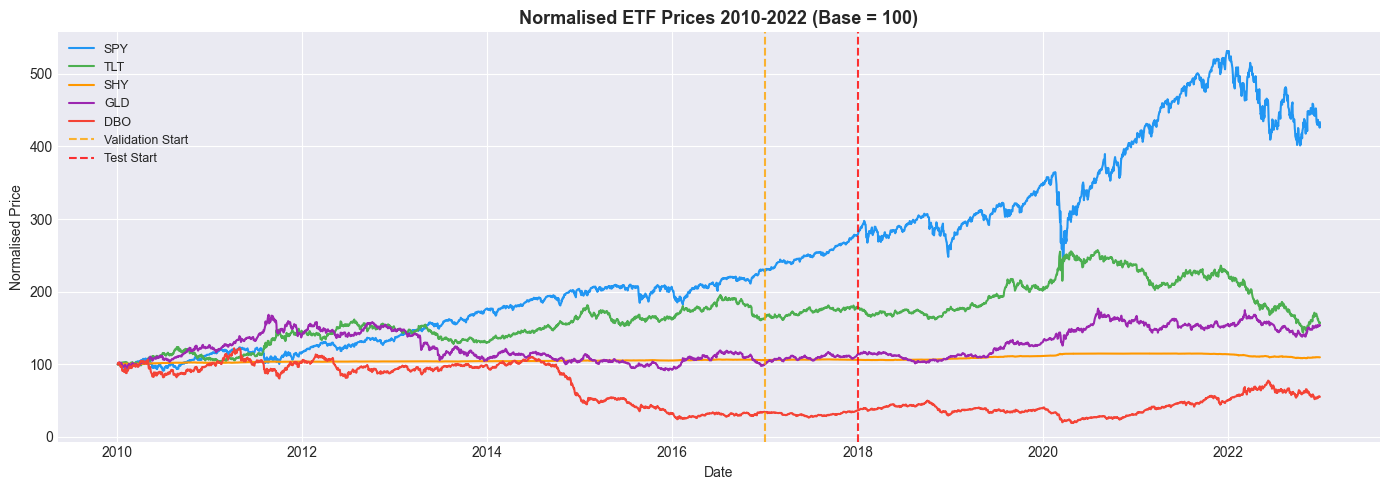

In [4]:
# Hitesh - Step 1b: Normalised Price Chart
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 5))
norm_prices = raw_data / raw_data.iloc[0] * 100
for i, sym in enumerate(SYMBOLS):
    ax.plot(norm_prices.index, norm_prices[sym],
            label=sym, color=COLORS[i], linewidth=1.5)
ax.axvline(pd.Timestamp(VAL_START),  color="orange", linestyle="--",
           alpha=0.8, linewidth=1.5, label="Validation Start")
ax.axvline(pd.Timestamp(TEST_START), color="red",    linestyle="--",
           alpha=0.8, linewidth=1.5, label="Test Start")
ax.set_title("Normalised ETF Prices 2010-2022 (Base = 100)",
             fontsize=13, fontweight="bold")
ax.set_ylabel("Normalised Price")
ax.set_xlabel("Date")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.savefig("step1_normalized_prices.png", dpi=150, bbox_inches="tight")
plt.show()


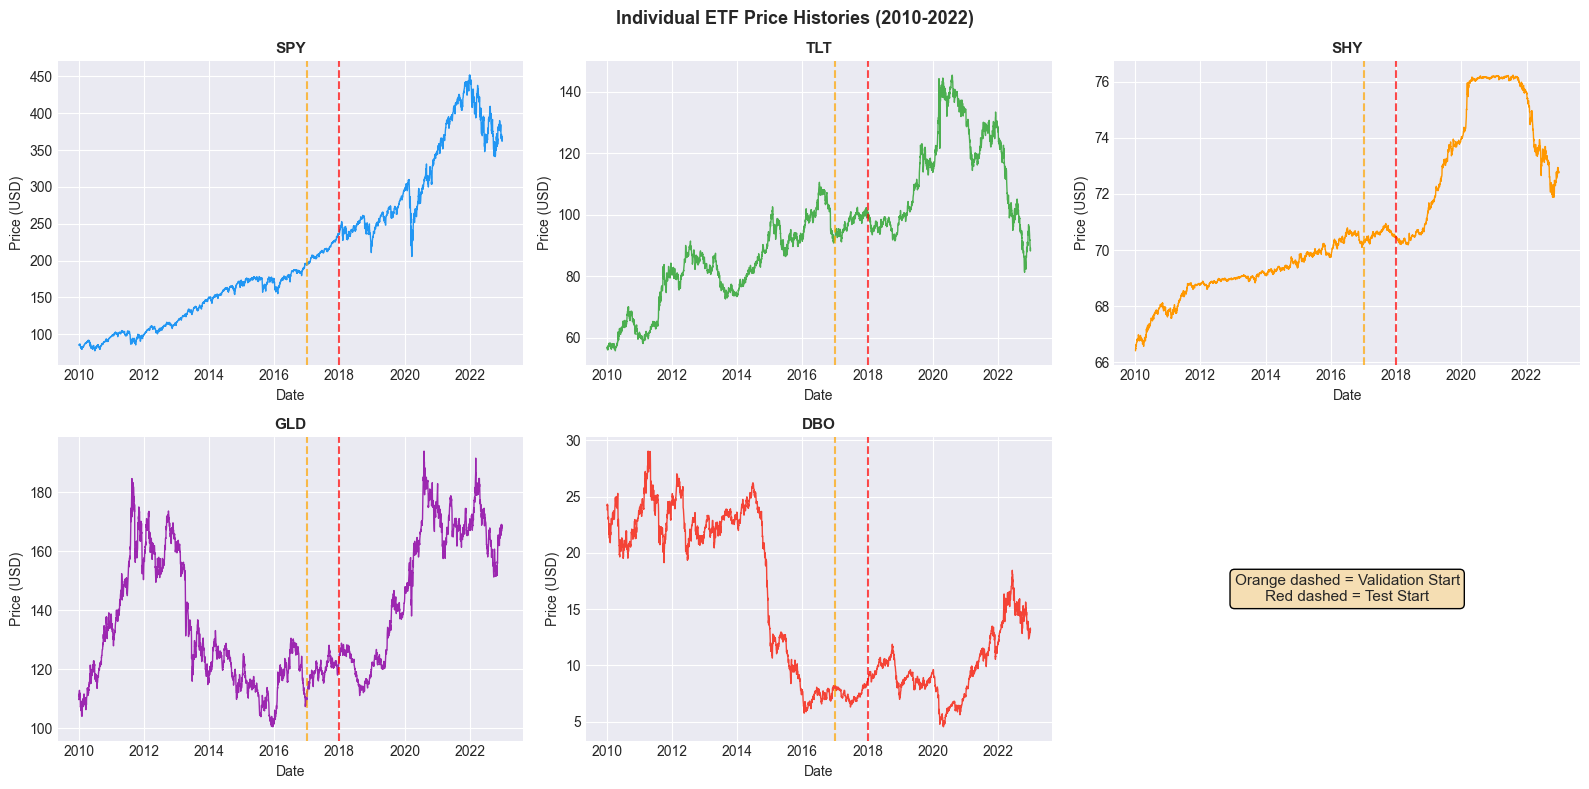

In [5]:
# Hitesh - Step 1b: Individual ETF Price Histories
# ---------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()
for i, sym in enumerate(SYMBOLS):
    axes[i].plot(raw_data.index, raw_data[sym], color=COLORS[i], linewidth=1)
    axes[i].axvline(pd.Timestamp(VAL_START),  color="orange", linestyle="--", alpha=0.7)
    axes[i].axvline(pd.Timestamp(TEST_START), color="red",    linestyle="--", alpha=0.7)
    axes[i].set_title(sym, fontsize=11, fontweight="bold")
    axes[i].set_ylabel("Price (USD)")
    axes[i].set_xlabel("Date")
    axes[i].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[i].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[5].axis("off")
axes[5].text(0.5, 0.5,
             "Orange dashed = Validation Start\nRed dashed = Test Start",
             ha="center", va="center", fontsize=11,
             bbox=dict(boxstyle="round", facecolor="wheat"))
fig.suptitle("Individual ETF Price Histories (2010-2022)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("step1_individual_prices.png", dpi=150, bbox_inches="tight")
plt.show()


In [6]:
# Hitesh - Step 1b: Summary Statistics
# ---------------------------------------------------------------
stats = returns.describe().T
stats["Skewness"]        = returns.skew()
stats["Kurtosis"]        = returns.kurtosis()
stats["Ann. Return"]     = returns.mean() * 252
stats["Ann. Volatility"] = returns.std()  * np.sqrt(252)
stats["Sharpe Ratio"]    = stats["Ann. Return"] / stats["Ann. Volatility"]

display_cols = ["mean", "std", "min", "max",
                "Skewness", "Kurtosis",
                "Ann. Return", "Ann. Volatility", "Sharpe Ratio"]
print("SUMMARY STATISTICS - Daily Log Returns (Full Period 2010-2022)")
print("=" * 70)
display(stats[display_cols].round(4))


SUMMARY STATISTICS - Daily Log Returns (Full Period 2010-2022)


,mean,std,min,max,Skewness,Kurtosis,Ann. Return,Ann. Volatility,Sharpe Ratio
Ticker,,,,,,,,,
DBO,-0.0002,0.0193,-0.1821,0.1010,-0.7273,5.9881,-0.0459,0.3058,-0.1502
GLD,0.0001,0.0099,-0.0919,0.0479,-0.5364,5.1555,0.0332,0.1572,0.2109
SHY,0.0000,0.0007,-0.0051,0.0054,0.0960,8.7477,0.0071,0.0110,0.6425
SPY,0.0004,0.0111,-0.1159,0.0867,-0.7304,11.5556,0.1130,0.1767,0.6397
TLT,0.0001,0.0095,-0.0690,0.0725,-0.0268,4.1476,0.0351,0.1510,0.2323


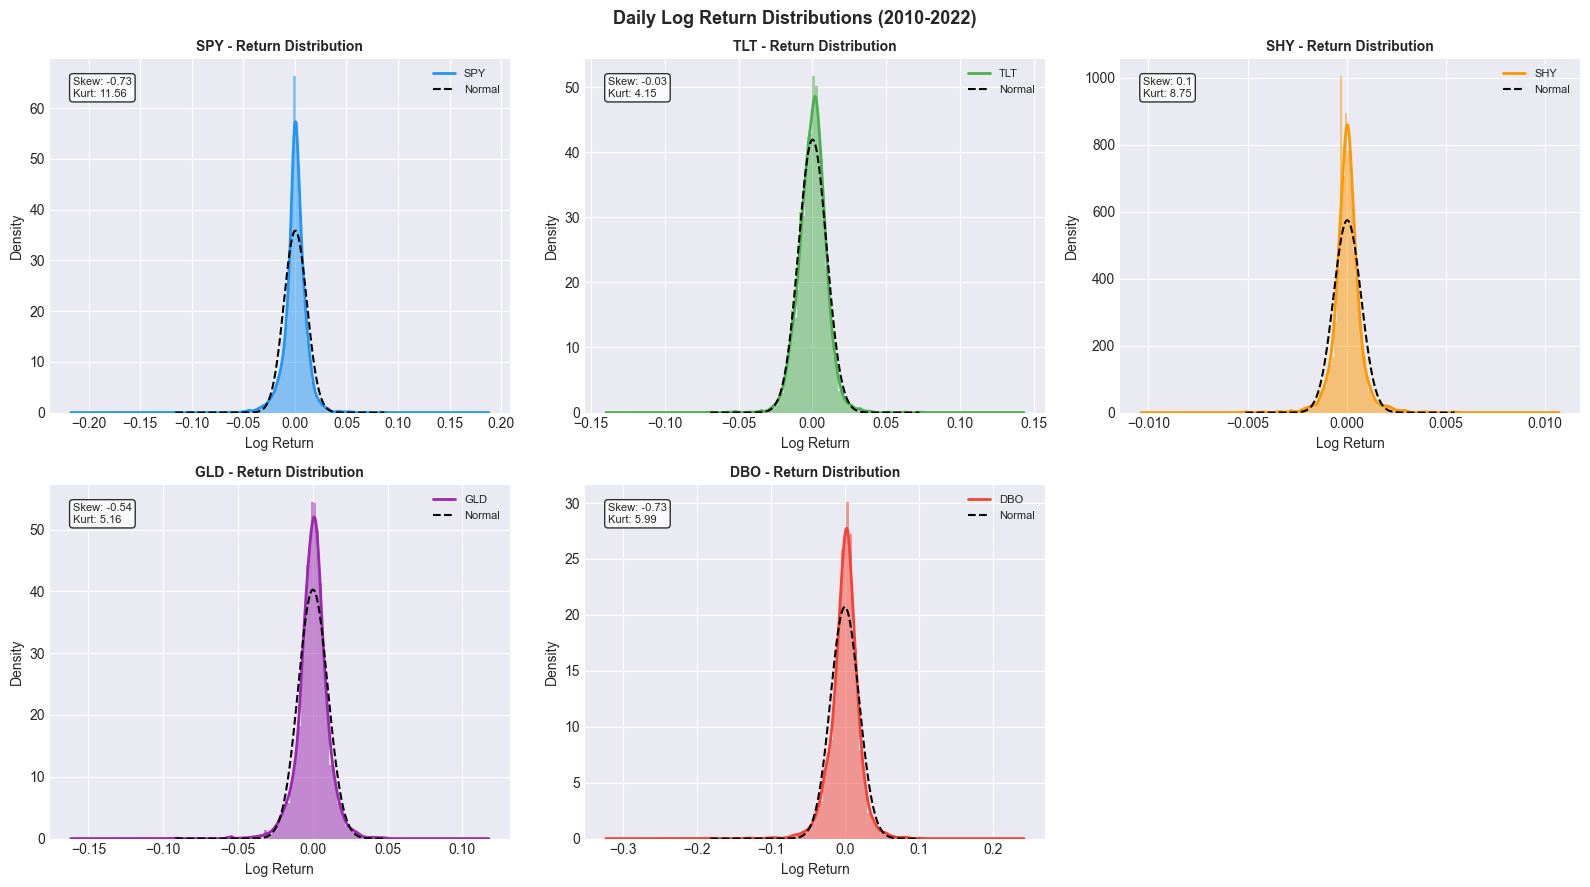

In [7]:
# Hitesh - Step 1b: Return Distribution Plots
# ---------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for i, sym in enumerate(SYMBOLS):
    ax  = axes[i]
    ret = returns[sym].dropna()
    ax.hist(ret, bins=80, density=True, alpha=0.5,
            color=COLORS[i], edgecolor="none")
    ret.plot.kde(ax=ax, color=COLORS[i], linewidth=2)
    mu, sigma = ret.mean(), ret.std()
    x = np.linspace(ret.min(), ret.max(), 300)
    ax.plot(x, norm.pdf(x, mu, sigma), "k--", linewidth=1.5, label="Normal")
    ax.set_title(sym + " - Return Distribution", fontsize=10, fontweight="bold")
    ax.set_xlabel("Log Return")
    ax.set_ylabel("Density")
    ax.legend(fontsize=8)
    info = "Skew: " + str(round(ret.skew(), 2)) + "\nKurt: " + str(round(ret.kurtosis(), 2))
    ax.text(0.05, 0.95, info, transform=ax.transAxes, fontsize=8, va="top",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))
axes[5].axis("off")
fig.suptitle("Daily Log Return Distributions (2010-2022)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("step1_return_distributions.png", dpi=150, bbox_inches="tight")
plt.show()


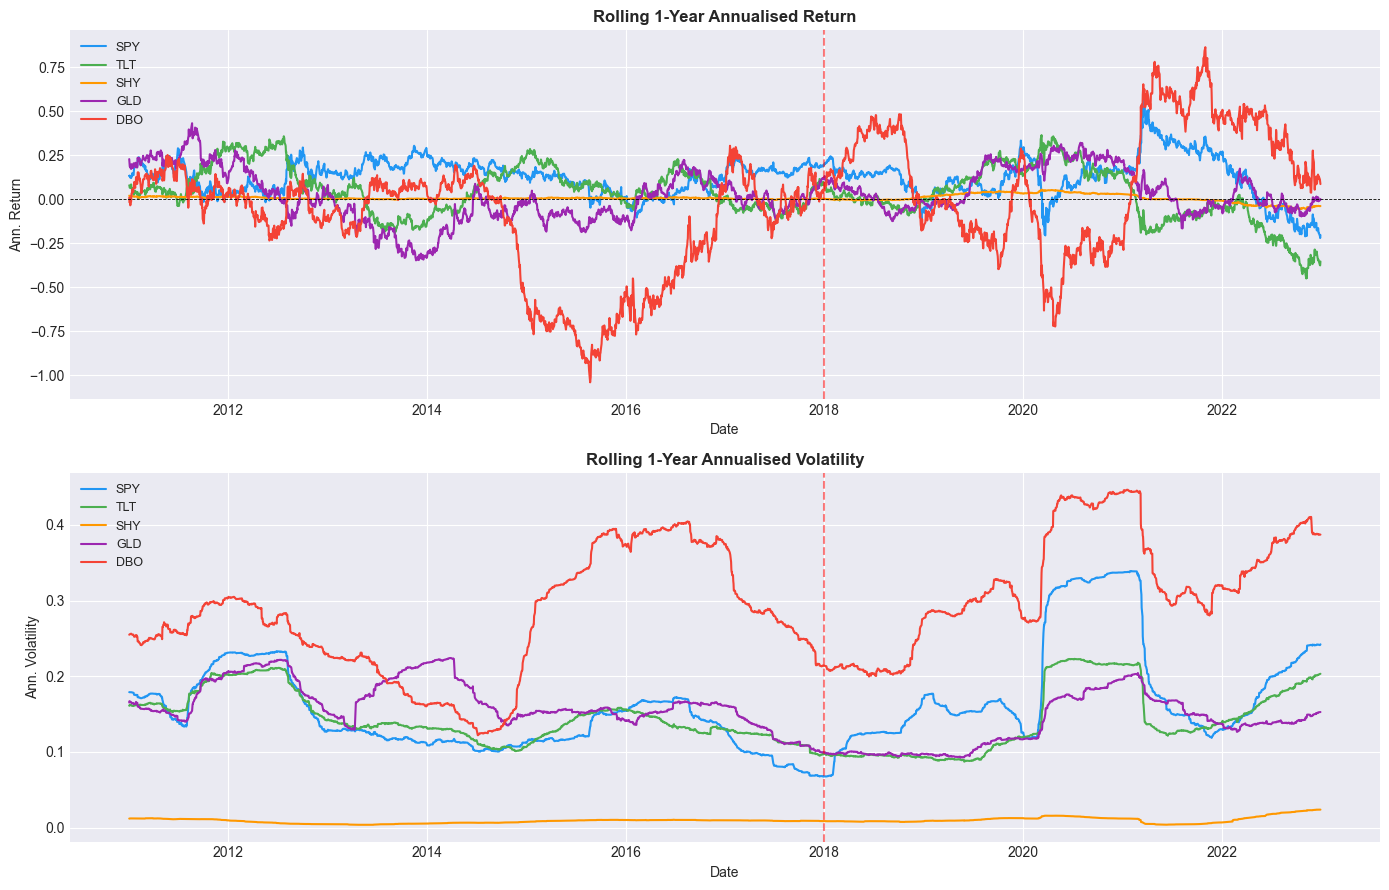

In [8]:
# Hitesh - Step 1b: Rolling Statistics
# ---------------------------------------------------------------
fig, axes = plt.subplots(2, 1, figsize=(14, 9))
window = 252
for i, sym in enumerate(SYMBOLS):
    axes[0].plot(returns.index, returns[sym].rolling(window).mean() * 252,
                 label=sym, color=COLORS[i], linewidth=1.5)
    axes[1].plot(returns.index, returns[sym].rolling(window).std() * np.sqrt(252),
                 label=sym, color=COLORS[i], linewidth=1.5)
for ax in axes:
    ax.axvline(pd.Timestamp(TEST_START), color="red", linestyle="--", alpha=0.5)
    ax.legend(loc="upper left", fontsize=9)
    ax.set_xlabel("Date")
axes[0].axhline(0, color="black", linewidth=0.6, linestyle="--")
axes[0].set_title("Rolling 1-Year Annualised Return",     fontsize=12, fontweight="bold")
axes[1].set_title("Rolling 1-Year Annualised Volatility", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Ann. Return")
axes[1].set_ylabel("Ann. Volatility")
plt.tight_layout()
plt.savefig("step1_rolling_stats.png", dpi=150, bbox_inches="tight")
plt.show()


In [9]:
# Hitesh - Step 1b: ADF Stationarity Tests
# ---------------------------------------------------------------
print("AUGMENTED DICKEY-FULLER STATIONARITY TEST RESULTS")
print("=" * 78)
print("{:<6} {:<16} {:<12} {:<12} | {:<16} {:<12} {:<12}".format(
    "ETF", "Price ADF", "p-value", "Stationary",
    "Return ADF", "p-value", "Stationary"))
print("-" * 78)
for sym in SYMBOLS:
    p_adf = adfuller(raw_data[sym].dropna(), autolag="AIC")
    r_adf = adfuller(returns[sym].dropna(),  autolag="AIC")
    print("{:<6} {:<16.4f} {:<12.4f} {:<12} | {:<16.4f} {:<12.6f} {:<12}".format(
        sym,
        p_adf[0], p_adf[1], "YES" if p_adf[1] < 0.05 else "NO",
        r_adf[0], r_adf[1], "YES" if r_adf[1] < 0.05 else "NO"))
print()
print("Conclusion: Prices are non-stationary (unit root present).")
print("            Log returns are stationary.")
print("            LSTM models will use daily log returns as inputs, not raw prices.")


AUGMENTED DICKEY-FULLER STATIONARITY TEST RESULTS
ETF    Price ADF        p-value      Stationary   | Return ADF       p-value      Stationary  
------------------------------------------------------------------------------
SPY    -0.3221          0.9223       NO           | -12.3862         0.000000     YES         
TLT    -1.8945          0.3346       NO           | -10.5470         0.000000     YES         
SHY    -1.3936          0.5853       NO           | -11.8648         0.000000     YES         
GLD    -1.7483          0.4064       NO           | -57.6503         0.000000     YES         
DBO    -1.3100          0.6246       NO           | -60.0524         0.000000     YES         

Conclusion: Prices are non-stationary (unit root present).
            Log returns are stationary.
            LSTM models will use daily log returns as inputs, not raw prices.


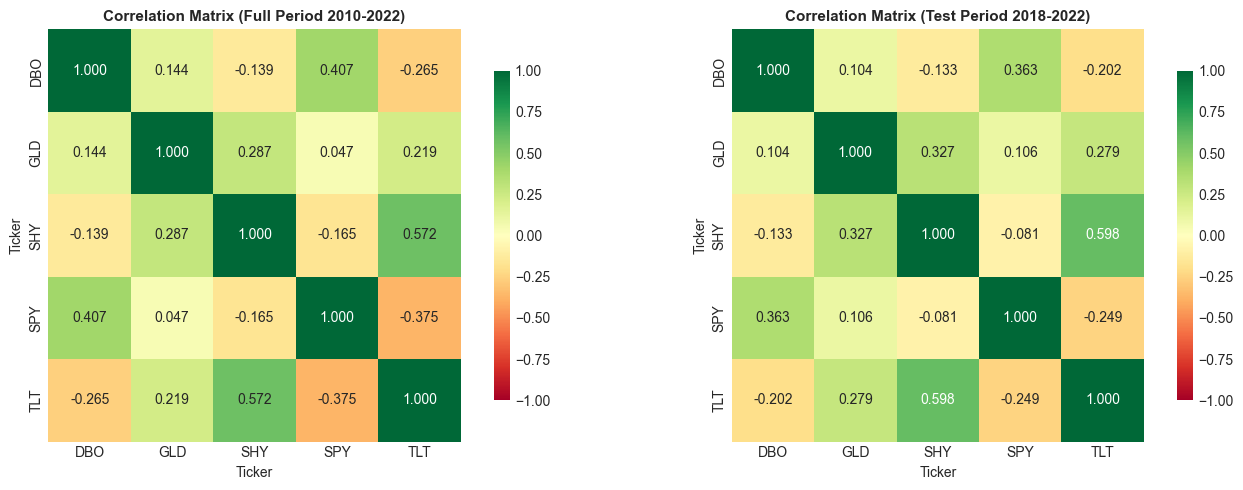

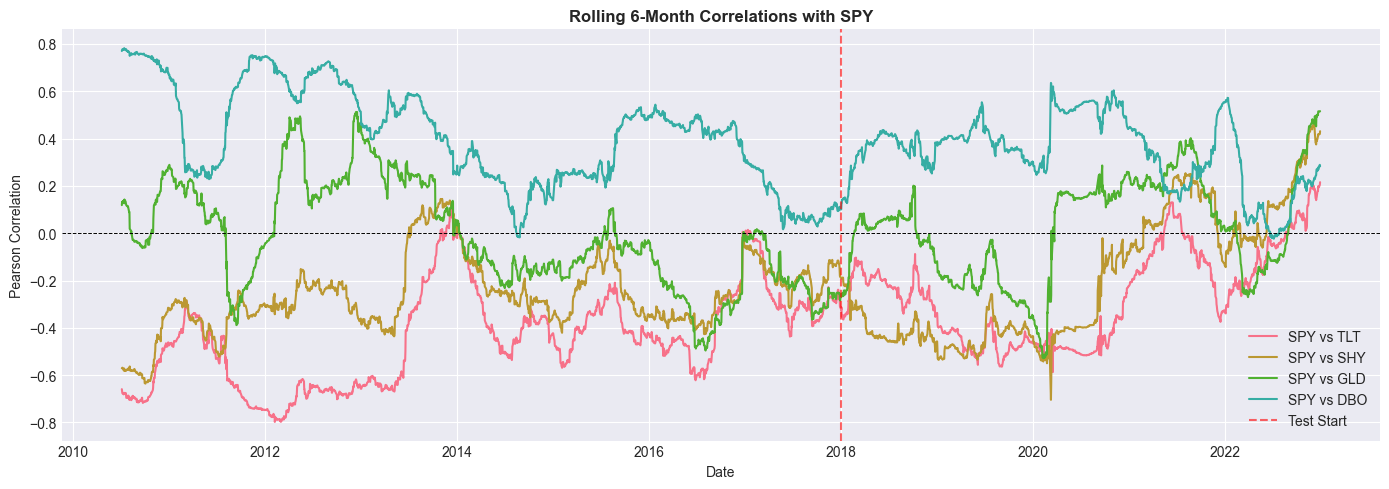

In [10]:
# Hitesh - Step 1b: Correlation Analysis
# ---------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, data, title in zip(
        axes,
        [returns, returns_test],
        ["Full Period 2010-2022", "Test Period 2018-2022"]):
    sns.heatmap(data.corr(), annot=True, fmt=".3f", cmap="RdYlGn",
                center=0, vmin=-1, vmax=1, ax=ax, square=True,
                cbar_kws={"shrink": 0.8})
    ax.set_title("Correlation Matrix (" + title + ")",
                 fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig("step1_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

# Rolling 6-month correlations with SPY
fig, ax = plt.subplots(figsize=(14, 5))
for sym in ["TLT", "SHY", "GLD", "DBO"]:
    ax.plot(returns.index,
            returns["SPY"].rolling(126).corr(returns[sym]),
            label="SPY vs " + sym, linewidth=1.5)
ax.axhline(0, color="black", linewidth=0.7, linestyle="--")
ax.axvline(pd.Timestamp(TEST_START), color="red", linestyle="--",
           alpha=0.6, label="Test Start")
ax.set_title("Rolling 6-Month Correlations with SPY",
             fontsize=12, fontweight="bold")
ax.set_ylabel("Pearson Correlation")
ax.set_xlabel("Date")
ax.legend()
plt.tight_layout()
plt.savefig("step1_rolling_corr.png", dpi=150, bbox_inches="tight")
plt.show()


---
---
# MEMBER 2 - Hitesh
## Role: Single-Output LSTM Models and Backtesting
## Covers: Step 2a - Preprocessing | Step 2b - In-Sample | Step 2c - OOS | Step 2d/e - Strategy
---
---


## Step 2: Single-Output LSTM Models

### Step 2a - Architecture and Preprocessing

**Prediction target:** 25-day ahead cumulative log return
**Input:** 30-day lookback of daily log returns (one sequence per ETF)

| Layer | Configuration |
|-------|---------------|
| Input | Shape (30, 1) |
| LSTM 1 | 64 units, return_sequences = True |
| Dropout 1 | rate = 0.2 |
| LSTM 2 | 32 units |
| Dropout 2 | rate = 0.2 |
| Dense | 16 units, ReLU |
| Output | 1 unit (25-day cumulative log return) |

Optimiser: Adam (lr = 0.001) | Loss: MSE | Early stopping: patience = 15


### Note on Validation Approach

A **fixed validation split** (Jan 2017 to Dec 2017) is used for hyperparameter
selection and early stopping. This is appropriate because:

1. The test set (Jan 2018 to Dec 2022) is fully held out and never seen during
   training or hyperparameter selection, preventing data leakage.
2. Early stopping with `restore_best_weights=True` selects the epoch that
   generalised best to the 2017 out-of-sample year.
3. Walk-forward expanding-window retraining would be ideal for a live deployment
   but is beyond the scope of this academic project.


In [11]:
# Hitesh - Step 2a: Data Preprocessing and Sequence Creation
# ---------------------------------------------------------------
def create_sequences(series, lookback=LOOKBACK, horizon=HORIZON):
    """
    Sliding-window sequence builder.
    X: (n, lookback) array of scaled returns
    y: scalar cumulative log return over next horizon days
    """
    X, y = [], []
    for i in range(lookback, len(series) - horizon + 1):
        X.append(series[i - lookback:i])
        y.append(series[i:i + horizon].sum())
    return np.array(X), np.array(y)


def prepare_single_output(symbol):
    """Scale and sequence-ify train / val / test data for one ETF symbol."""
    scaler = MinMaxScaler(feature_range=(-1, 1))
    tr = scaler.fit_transform(returns_train[symbol].values.reshape(-1, 1)).flatten()
    va = scaler.transform(returns_val[symbol].values.reshape(-1, 1)).flatten()
    te = scaler.transform(returns_test[symbol].values.reshape(-1, 1)).flatten()
    X_tr, y_tr = create_sequences(tr)
    X_va, y_va = create_sequences(va)
    X_te, y_te = create_sequences(te)
    return (X_tr.reshape(-1, LOOKBACK, 1), y_tr,
            X_va.reshape(-1, LOOKBACK, 1), y_va,
            X_te.reshape(-1, LOOKBACK, 1), y_te,
            scaler)


data_dict = {sym: prepare_single_output(sym) for sym in SYMBOLS}

print("Sequence Shapes per ETF")
print("-" * 50)
for sym in SYMBOLS:
    X_tr, y_tr, X_va, y_va, X_te, y_te, _ = data_dict[sym]
    print("{:<5}  train: {}  val: {}  test: {}".format(
        sym, X_tr.shape, X_va.shape, X_te.shape))


Sequence Shapes per ETF
--------------------------------------------------
SPY    train: (1707, 30, 1)  val: (197, 30, 1)  test: (1204, 30, 1)
TLT    train: (1707, 30, 1)  val: (197, 30, 1)  test: (1204, 30, 1)
SHY    train: (1707, 30, 1)  val: (197, 30, 1)  test: (1204, 30, 1)
GLD    train: (1707, 30, 1)  val: (197, 30, 1)  test: (1204, 30, 1)
DBO    train: (1707, 30, 1)  val: (197, 30, 1)  test: (1204, 30, 1)


In [12]:
# Hitesh - Step 2a: LSTM Model Architecture
# ---------------------------------------------------------------
def build_single_lstm(lookback=LOOKBACK, u1=64, u2=32, dropout=0.2, lr=1e-3):
    model = Sequential([
        LSTM(u1, input_shape=(lookback, 1), return_sequences=True),
        Dropout(dropout),
        LSTM(u2, return_sequences=False),
        Dropout(dropout),
        Dense(16, activation="relu"),
        Dense(1)
    ])
    model.compile(optimizer=Adam(lr), loss="mse", metrics=["mae"])
    return model

build_single_lstm().summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 30, 64)              │          16,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 30, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 32)                  │          12,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

### Hyperparameter Justification

| Hyperparameter | Value | Justification |
|----------------|-------|---------------|
| Lookback window | 30 days | Captures one calendar month of return momentum |
| Prediction horizon | 25 days | Approx. one trading month; balances cost vs. signal decay |
| LSTM units layer 1 | 64 | Enough capacity for non-linear patterns on ~1,800 samples |
| LSTM units layer 2 | 32 | Compresses representation before output (encoder style) |
| Dropout rate | 0.2 | Standard regularisation; prevents LSTM cell co-adaptation |
| Learning rate | 0.001 | Adam default; ReduceLROnPlateau halves it on plateau |
| Batch size | 32 | Balances gradient noise vs. training speed |
| Early stopping patience | 15 | Allows escape from local minima before halting |
| Dense activation | ReLU | Avoids vanishing gradient in fully-connected layers |
| Output activation | Linear | Correct for unbounded regression target |


In [13]:
# Hitesh - Step 2a: Train One LSTM Per ETF
# ---------------------------------------------------------------
callbacks = [
    EarlyStopping(monitor="val_loss", patience=15,
                  restore_best_weights=True, verbose=0),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=7, verbose=0)
]

models    = {}
histories = {}

print("Training single-output LSTM models...")
print("-" * 55)
for sym in SYMBOLS:
    X_tr, y_tr, X_va, y_va, _, _, _ = data_dict[sym]
    model = build_single_lstm()
    hist  = model.fit(X_tr, y_tr, validation_data=(X_va, y_va),
                      epochs=EPOCHS, batch_size=BATCH_SIZE,
                      callbacks=callbacks, verbose=0)
    models[sym]    = model
    histories[sym] = hist
    print("{:<5}  best epoch: {:3d}  val_loss: {:.6f}".format(
        sym,
        np.argmin(hist.history["val_loss"]) + 1,
        min(hist.history["val_loss"])))
print()
print("All 5 single-output models trained.")


Training single-output LSTM models...
-------------------------------------------------------
SPY    best epoch:   1  val_loss: 0.063035
TLT    best epoch:   2  val_loss: 0.205501
SHY    best epoch:   4  val_loss: 0.535043
GLD    best epoch:   3  val_loss: 0.170588
DBO    best epoch:  15  val_loss: 0.509109

All 5 single-output models trained.


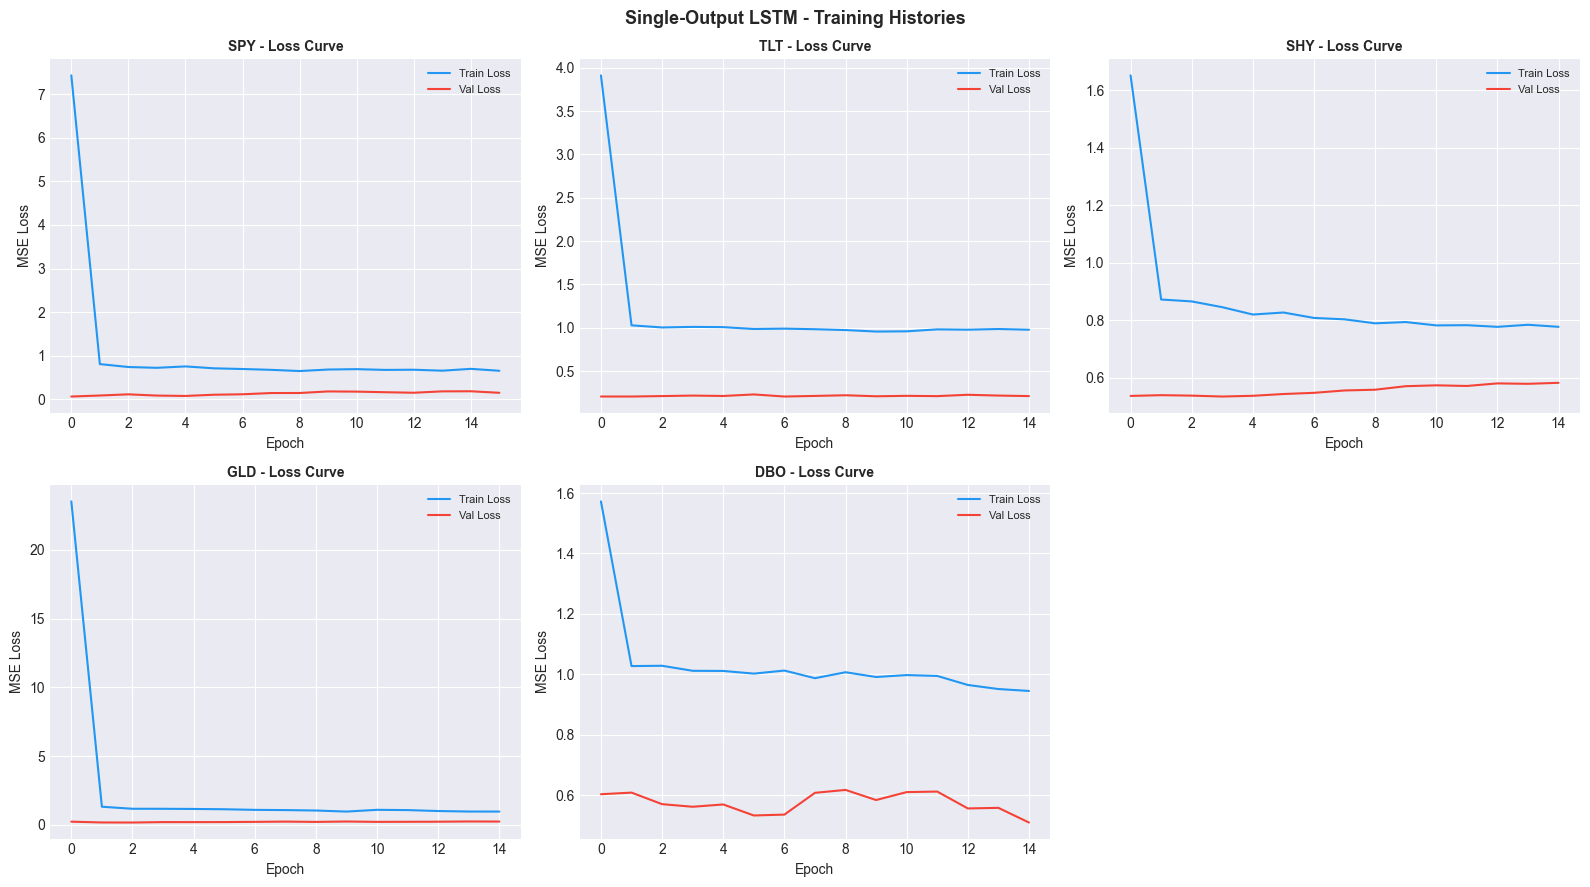

In [14]:
# Hitesh - Training and Validation Loss Curves
# ---------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for i, sym in enumerate(SYMBOLS):
    h = histories[sym].history
    axes[i].plot(h["loss"],     label="Train Loss", color="#2196F3", linewidth=1.5)
    axes[i].plot(h["val_loss"], label="Val Loss",   color="#F44336", linewidth=1.5)
    axes[i].set_title(sym + " - Loss Curve", fontsize=10, fontweight="bold")
    axes[i].set_xlabel("Epoch")
    axes[i].set_ylabel("MSE Loss")
    axes[i].legend(fontsize=8)
axes[5].axis("off")
fig.suptitle("Single-Output LSTM - Training Histories",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("step2_training_history.png", dpi=150, bbox_inches="tight")
plt.show()


In [15]:
# Hitesh - Evaluation Helper Function (shared with Member 3)
# ---------------------------------------------------------------
def evaluate_model(model, X, y):
    """
    Compute RMSE, MAE, Directional Accuracy, and Pearson Correlation.
    Returns a metrics dict and the predictions array.
    """
    y_pred  = model.predict(X, verbose=0).flatten()
    rmse    = np.sqrt(mean_squared_error(y, y_pred))
    mae     = mean_absolute_error(y, y_pred)
    dir_acc = np.mean(np.sign(y_pred) == np.sign(y)) * 100
    corr    = np.corrcoef(y, y_pred)[0, 1]
    return {"RMSE": rmse, "MAE": mae,
            "Dir Acc (%)": dir_acc, "Correlation": corr}, y_pred


In [16]:
# Hitesh - Step 2b: In-Sample Performance (Training Set)
# ---------------------------------------------------------------
print("IN-SAMPLE PERFORMANCE - Training Set")
print("=" * 65)
in_sample_results = {}
for sym in SYMBOLS:
    X_tr, y_tr, _, _, _, _, _ = data_dict[sym]
    metrics, _ = evaluate_model(models[sym], X_tr, y_tr)
    in_sample_results[sym] = metrics
    print("{:<5}  RMSE={:.5f}  Dir Acc={:.1f}%  Corr={:.4f}".format(
        sym, metrics["RMSE"], metrics["Dir Acc (%)"], metrics["Correlation"]))
print()
display(pd.DataFrame(in_sample_results).T.round(4))


IN-SAMPLE PERFORMANCE - Training Set
SPY    RMSE=0.71197  Dir Acc=100.0%  Corr=0.0354
TLT    RMSE=0.92922  Dir Acc=100.0%  Corr=0.0229
SHY    RMSE=0.92352  Dir Acc=99.0%  Corr=-0.1627
GLD    RMSE=0.80652  Dir Acc=100.0%  Corr=-0.0234
DBO    RMSE=1.00649  Dir Acc=91.2%  Corr=0.1757



,RMSE,MAE,Dir Acc (%),Correlation
SPY,0.7120,0.5290,100.0000,0.0354
TLT,0.9292,0.7298,100.0000,0.0229
SHY,0.9235,0.6882,99.0041,-0.1627
GLD,0.8065,0.6494,100.0000,-0.0234
DBO,1.0065,0.7840,91.1541,0.1757


OUT-OF-SAMPLE PERFORMANCE - Test Period 2018-2022
SPY    RMSE=1.10543  Dir Acc=99.3%  Corr=0.0103
TLT    RMSE=1.07531  Dir Acc=100.0%  Corr=0.0619
SHY    RMSE=1.97915  Dir Acc=89.3%  Corr=0.3404
GLD    RMSE=0.62849  Dir Acc=100.0%  Corr=-0.0575
DBO    RMSE=1.26243  Dir Acc=90.4%  Corr=0.1534



,RMSE,MAE,Dir Acc (%),Correlation
SPY,1.1054,0.7482,99.2525,0.0103
TLT,1.0753,0.8300,100.0000,0.0619
SHY,1.9792,1.3273,89.2857,0.3404
GLD,0.6285,0.5160,100.0000,-0.0575
DBO,1.2624,1.0204,90.4485,0.1534


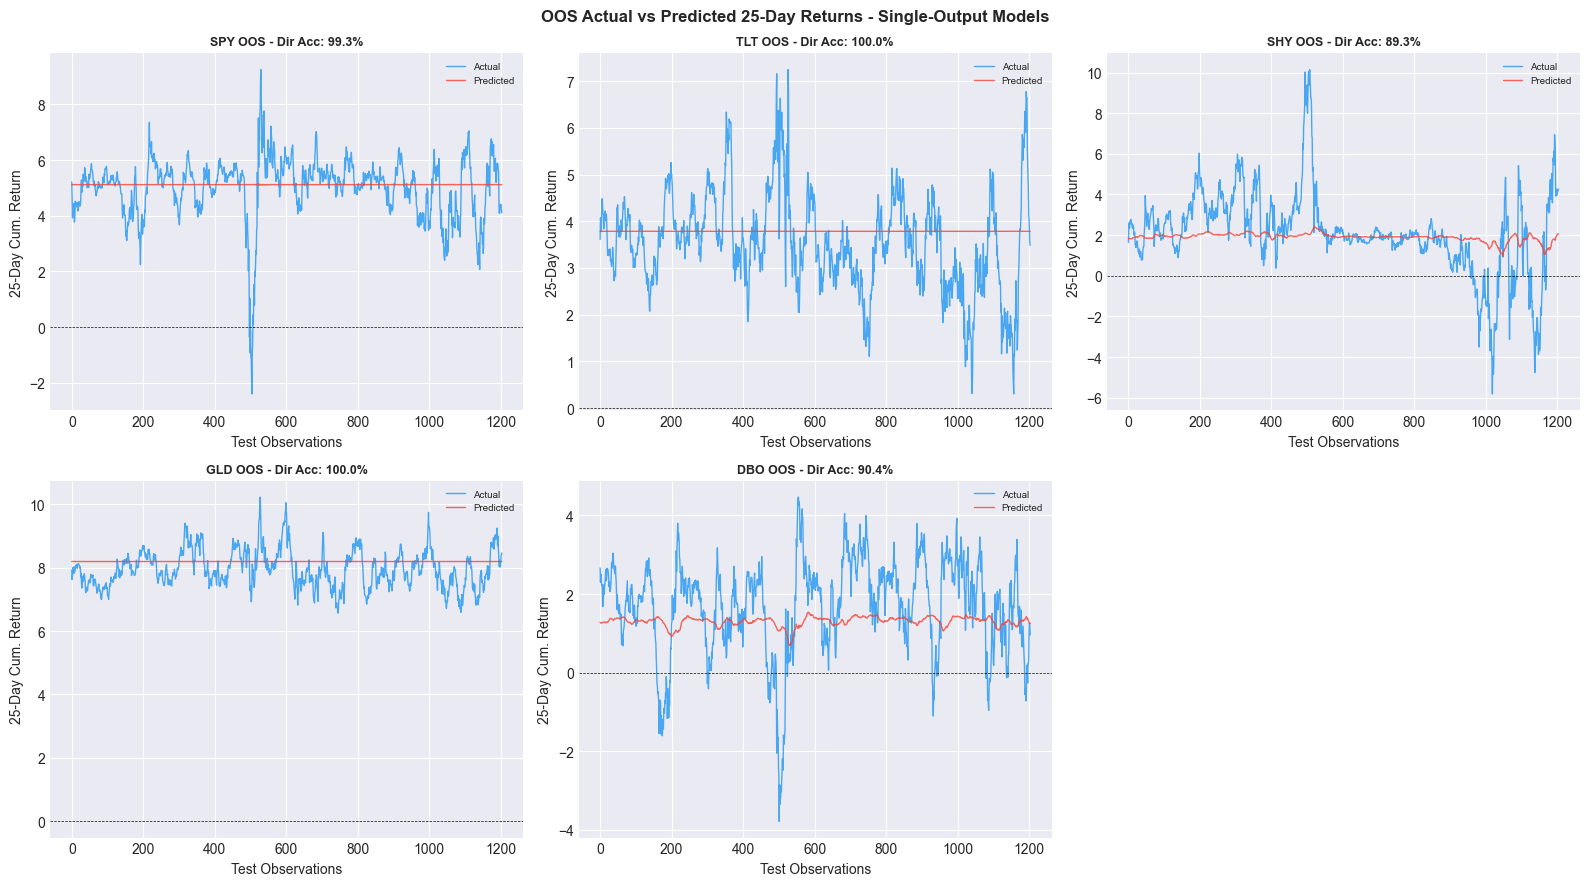

In [17]:
# Hitesh - Step 2c: Out-of-Sample Performance (Test Period 2018-2022)
# ---------------------------------------------------------------
print("OUT-OF-SAMPLE PERFORMANCE - Test Period 2018-2022")
print("=" * 65)
oos_results = {}
oos_preds   = {}
for sym in SYMBOLS:
    _, _, _, _, X_te, y_te, _ = data_dict[sym]
    metrics, y_pred = evaluate_model(models[sym], X_te, y_te)
    oos_results[sym] = metrics
    oos_preds[sym]   = {"y_pred": y_pred, "y_true": y_te}
    print("{:<5}  RMSE={:.5f}  Dir Acc={:.1f}%  Corr={:.4f}".format(
        sym, metrics["RMSE"], metrics["Dir Acc (%)"], metrics["Correlation"]))
print()
display(pd.DataFrame(oos_results).T.round(4))

# Actual vs Predicted
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for i, sym in enumerate(SYMBOLS):
    axes[i].plot(oos_preds[sym]["y_true"], label="Actual",
                 color="#2196F3", linewidth=1, alpha=0.8)
    axes[i].plot(oos_preds[sym]["y_pred"], label="Predicted",
                 color="#F44336", linewidth=1, alpha=0.8)
    axes[i].axhline(0, color="black", linewidth=0.5, linestyle="--")
    axes[i].set_title("{} OOS - Dir Acc: {:.1f}%".format(
        sym, oos_results[sym]["Dir Acc (%)"]), fontsize=9, fontweight="bold")
    axes[i].set_xlabel("Test Observations")
    axes[i].set_ylabel("25-Day Cum. Return")
    axes[i].legend(fontsize=7)
axes[5].axis("off")
fig.suptitle("OOS Actual vs Predicted 25-Day Returns - Single-Output Models",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("step2_oos_predictions.png", dpi=150, bbox_inches="tight")
plt.show()


In [18]:
# Hitesh - Information Coefficient (IC) Analysis
# ---------------------------------------------------------------
# IC (Pearson) = linear correlation between predicted and actual returns
# Rank IC (Spearman) = rank-order correlation, more robust to outliers
# IC t-stat > 1.96 implies statistically significant predictive skill

from scipy.stats import spearmanr

print("INFORMATION COEFFICIENT ANALYSIS - Out-of-Sample (Single-Output)")
print("=" * 65)
print("{:<6} {:>12} {:>14} {:>12}".format(
    "ETF", "Pearson IC", "Spearman IC", "IC t-stat"))
print("-" * 46)

ic_results = {}
for sym in SYMBOLS:
    y_t  = oos_preds[sym]["y_true"]
    y_p  = oos_preds[sym]["y_pred"]
    pic  = np.corrcoef(y_t, y_p)[0, 1]
    sic  = spearmanr(y_t, y_p)[0]
    n    = len(y_t)
    tst  = pic * np.sqrt(n - 2) / np.sqrt(max(1 - pic**2, 1e-9))
    ic_results[sym] = {"Pearson IC": pic, "Spearman IC": sic, "IC t-stat": tst}
    print("{:<6} {:>12.4f} {:>14.4f} {:>12.4f}".format(sym, pic, sic, tst))

ic_df = pd.DataFrame(ic_results).T
print()
print("Mean Pearson IC : {:.4f}".format(ic_df["Pearson IC"].mean()))
print("Mean Spearman IC: {:.4f}".format(ic_df["Spearman IC"].mean()))
print()
print("Interpretation:")
print("  IC > 0.05 is generally considered useful in quantitative finance.")
print("  IC t-stat > 1.96 indicates statistically significant predictability.")


INFORMATION COEFFICIENT ANALYSIS - Out-of-Sample (Single-Output)
ETF      Pearson IC    Spearman IC    IC t-stat
----------------------------------------------
SPY          0.0103         0.0228       0.3576
TLT          0.0619         0.0900       2.1507
SHY          0.3404         0.3878      12.5529
GLD         -0.0575        -0.0358      -1.9974
DBO          0.1534         0.0674       5.3815

Mean Pearson IC : 0.1017
Mean Spearman IC: 0.1064

Interpretation:
  IC > 0.05 is generally considered useful in quantitative finance.
  IC t-stat > 1.96 indicates statistically significant predictability.


### Step 2d and 2e - Trading Strategy and Backtest

**Strategy rules (rebalanced every 25 trading days):**

| Rank by Predicted Return | Position | Weight per ETF |
|--------------------------|----------|----------------|
| 4th and 5th (top 2) | Long | +50% |
| 1st and 2nd (bottom 2) | Short | -50% |
| 3rd (middle) | Neutral | 0% |

**Benchmark:** Equal-weight buy-and-hold of all 5 ETFs.


Step 2 Strategy - Test Period Performance
--------------------------------------------------
Total Cumulative Return : 11.09%
Ann. Return (/ 5 years) : 2.22%
Std Dev per 25-day pd   : 5.81%
Number of rebalances    : 48

Equal-Weight Buy-and-Hold Benchmark
--------------------------------------------------
Total Return            : 21.71%
Ann. Volatility         : 10.21%


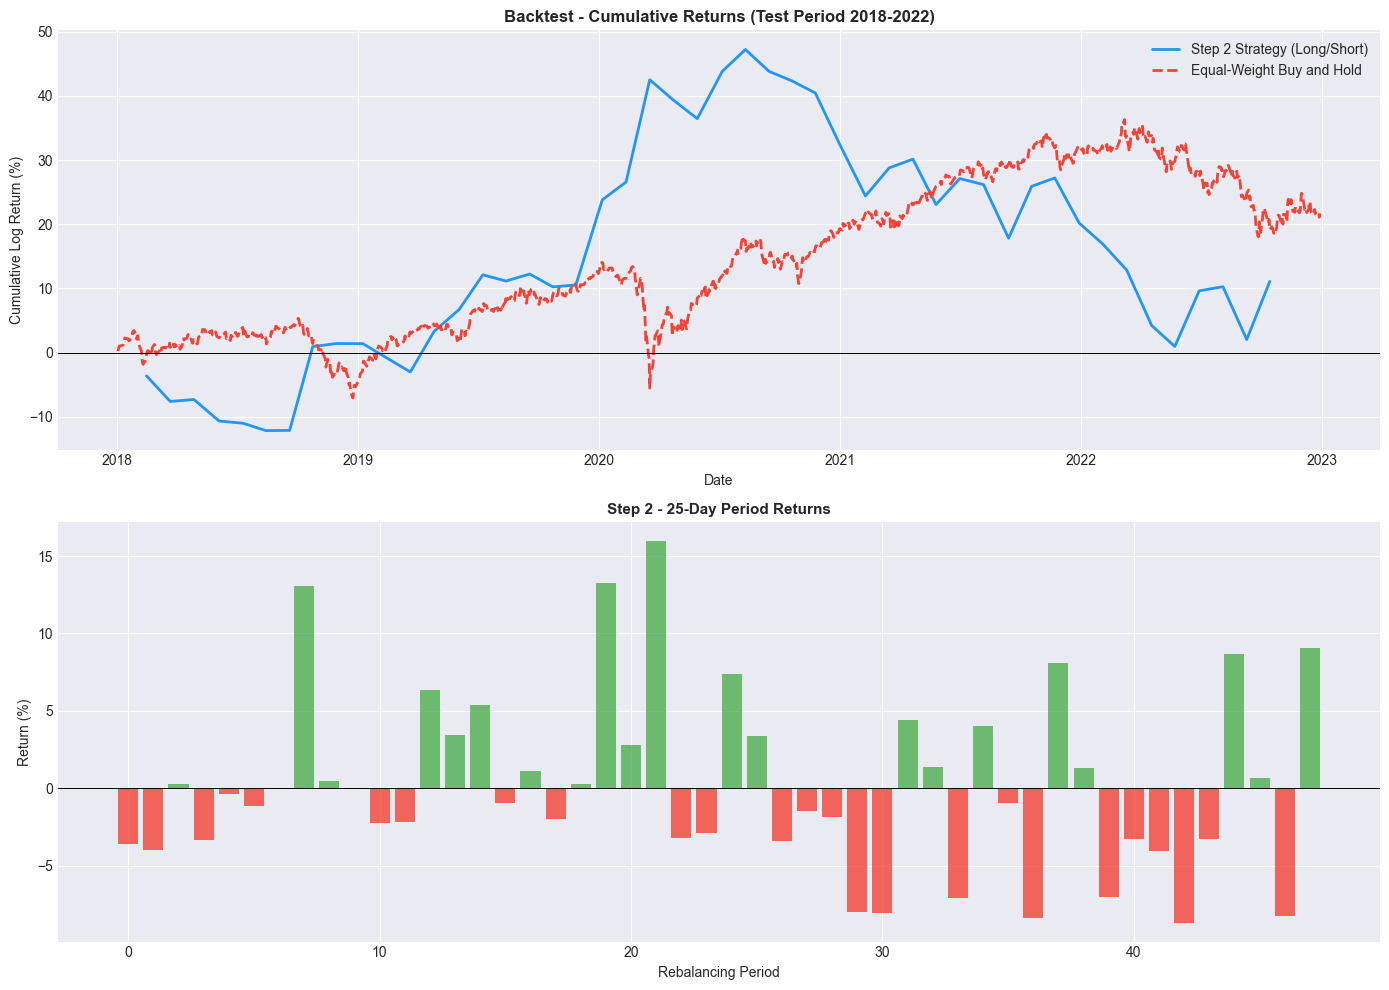

In [19]:
# Hitesh - Step 2d and 2e: Trading Strategy and Backtest
# ---------------------------------------------------------------
test_ret_dates = returns_test.index
pred_start_idx = list(range(LOOKBACK, len(returns_test) - HORIZON + 1))
pred_dates     = test_ret_dates[pred_start_idx]
n_preds        = min(len(oos_preds[s]["y_pred"]) for s in SYMBOLS)
pred_dates     = pred_dates[:n_preds]

pred_df2       = pd.DataFrame(
    {sym: oos_preds[sym]["y_pred"][:n_preds] for sym in SYMBOLS},
    index=pred_dates
)

rebal2         = pred_df2.index[::HORIZON]
strat2_returns = []
strat2_dates   = []

for j, rd in enumerate(rebal2[:-1]):
    next_rd   = rebal2[j + 1]
    ranks     = pred_df2.loc[rd].rank(ascending=True)
    positions = {}
    for sym in SYMBOLS:
        if ranks[sym] >= 4:   positions[sym] =  0.5
        elif ranks[sym] <= 2: positions[sym] = -0.5
        else:                 positions[sym] =  0.0
    mask    = (returns.index >= rd) & (returns.index < next_rd)
    per_ret = returns.loc[mask].sum()
    strat2_returns.append(sum(positions[sym] * per_ret[sym] for sym in SYMBOLS))
    strat2_dates.append(rd)

strat2     = pd.Series(strat2_returns, index=strat2_dates)
strat2_cum = strat2.cumsum()

ew_daily  = returns_test[SYMBOLS].mean(axis=1)
ew_cumret = ew_daily.cumsum()
ew_total  = ew_daily.sum()

print("Step 2 Strategy - Test Period Performance")
print("-" * 50)
print("Total Cumulative Return : {:.2f}%".format(strat2.sum() * 100))
print("Ann. Return (/ 5 years) : {:.2f}%".format(strat2.sum() / 5 * 100))
print("Std Dev per 25-day pd   : {:.2f}%".format(strat2.std() * 100))
print("Number of rebalances    :", len(strat2))
print()
print("Equal-Weight Buy-and-Hold Benchmark")
print("-" * 50)
print("Total Return            : {:.2f}%".format(ew_total * 100))
print("Ann. Volatility         : {:.2f}%".format(ew_daily.std() * np.sqrt(252) * 100))

fig, axes = plt.subplots(2, 1, figsize=(14, 10))
axes[0].plot(strat2_cum.index, strat2_cum * 100,
             label="Step 2 Strategy (Long/Short)", color="#2196F3", linewidth=2)
axes[0].plot(ew_cumret.index, ew_cumret * 100,
             label="Equal-Weight Buy and Hold", color="#F44336",
             linewidth=2, linestyle="--")
axes[0].axhline(0, color="black", linewidth=0.7)
axes[0].set_title("Backtest - Cumulative Returns (Test Period 2018-2022)",
                  fontsize=12, fontweight="bold")
axes[0].set_ylabel("Cumulative Log Return (%)")
axes[0].set_xlabel("Date")
axes[0].legend(fontsize=10)
axes[1].bar(range(len(strat2)), strat2 * 100,
            color=["#4CAF50" if r > 0 else "#F44336" for r in strat2], alpha=0.8)
axes[1].axhline(0, color="black", linewidth=0.7)
axes[1].set_title("Step 2 - 25-Day Period Returns", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Rebalancing Period")
axes[1].set_ylabel("Return (%)")
plt.tight_layout()
plt.savefig("step2_backtest.png", dpi=150, bbox_inches="tight")
plt.show()


STEP 2 STRATEGY PERFORMANCE METRICS vs BENCHMARK


,Step 2 - Single-Output,EW Buy and Hold
Total Return (%),11.0900,21.7100
Ann. Return (%),2.3300,4.1300
Ann. Volatility (%),18.4600,9.4100
Sharpe Ratio,0.1262,0.4387
Max Drawdown (%),-38.7600,-14.0400
Calmar Ratio,0.0601,0.2942
Win Rate (%),45.8300,66.0400
Avg Win per Period (%),5.0322,1.9226
Avg Loss per Period (%),-3.8315,-2.5322
Profit Factor,1.3134,0.7593


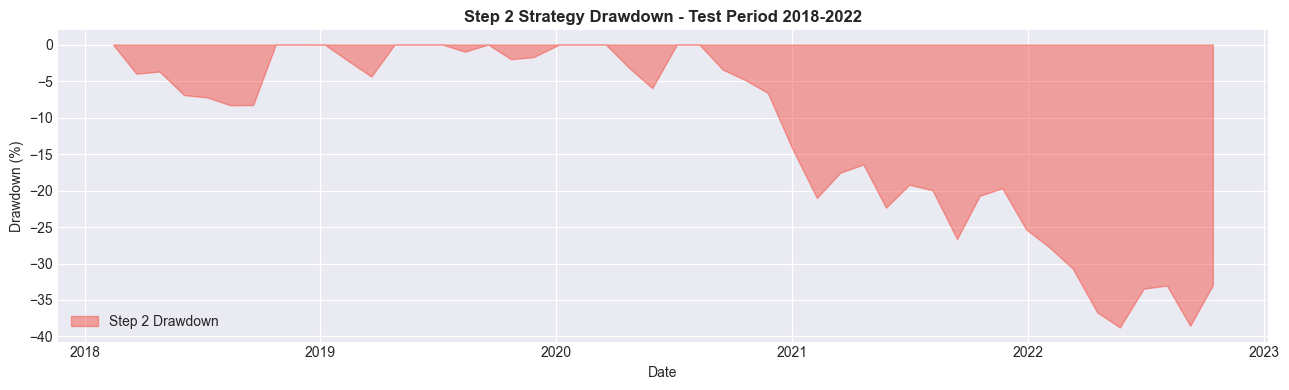

In [20]:
# Hitesh - Comprehensive Strategy Performance Metrics (Step 2)
# ---------------------------------------------------------------
def strategy_metrics(ret_series, ppy=252/25):
    """
    Full set of risk-adjusted performance metrics.
    ppy: rebalancing periods per year (~10.08 for 25-day rebalancing)
    """
    r          = ret_series.dropna()
    total_ret  = r.sum()
    ann_ret    = r.mean()  * ppy
    ann_vol    = r.std()   * np.sqrt(ppy)
    sharpe     = ann_ret   / ann_vol if ann_vol > 0 else np.nan
    cum        = (1 + r).cumprod()
    roll_max   = cum.cummax()
    drawdown   = (cum - roll_max) / roll_max
    max_dd     = drawdown.min()
    calmar     = ann_ret / abs(max_dd) if max_dd < 0 else np.nan
    win_rate   = (r > 0).sum() / len(r) * 100
    avg_win    = r[r > 0].mean() * 100 if (r > 0).any() else 0.0
    avg_loss   = r[r < 0].mean() * 100 if (r < 0).any() else 0.0
    pf         = abs(avg_win / avg_loss) if avg_loss != 0 else np.nan
    return {
        "Total Return (%)":    round(total_ret * 100, 2),
        "Ann. Return (%)":     round(ann_ret   * 100, 2),
        "Ann. Volatility (%)": round(ann_vol   * 100, 2),
        "Sharpe Ratio":        round(sharpe,          4),
        "Max Drawdown (%)":    round(max_dd    * 100, 2),
        "Calmar Ratio":        round(calmar,          4),
        "Win Rate (%)":        round(win_rate,        2),
        "Avg Win per Period (%)":  round(avg_win,     4),
        "Avg Loss per Period (%)": round(avg_loss,    4),
        "Profit Factor":       round(pf,              4),
    }

ppy = 252 / 25
ew_25d    = ew_daily.resample("25B").sum()
m_strat2  = strategy_metrics(strat2,  ppy)
m_ew      = strategy_metrics(ew_25d,  ppy)

metrics_table = pd.DataFrame({
    "Step 2 - Single-Output": m_strat2,
    "EW Buy and Hold":        m_ew
})
print("STEP 2 STRATEGY PERFORMANCE METRICS vs BENCHMARK")
print("=" * 60)
display(metrics_table)

# Drawdown chart
fig, ax = plt.subplots(figsize=(13, 4))
cum2 = (1 + strat2).cumprod()
dd2  = ((cum2 - cum2.cummax()) / cum2.cummax() * 100)
ax.fill_between(dd2.index, dd2.values, 0, alpha=0.45,
                color="#F44336", label="Step 2 Drawdown")
ax.set_title("Step 2 Strategy Drawdown - Test Period 2018-2022",
             fontsize=12, fontweight="bold")
ax.set_ylabel("Drawdown (%)")
ax.set_xlabel("Date")
ax.legend()
plt.tight_layout()
plt.savefig("step2_drawdown.png", dpi=150, bbox_inches="tight")
plt.show()


---
---
# MEMBER 3 - Pratik
## Role: Multi-Output LSTM Model and Integration Lead
## Covers: Step 3a - Architecture | Step 3b - Evaluation | Step 3c/d - Strategy and Comparison
---
---


## Step 3: Multi-Output LSTM Model

### Step 3a - Architecture

A single unified model takes the 30-day return history of all 5 ETFs and
simultaneously predicts the 25-day ahead return for all 5 ETFs.

**Architecture:**

- 5 parallel LSTM branches (one per ETF): LSTM(64) -> Dropout -> LSTM(32) -> Dropout
- All branches merged via Concatenate layer
- Shared representation: Dense(64, ReLU) -> Dropout(0.2) -> Dense(32, ReLU)
- 5 independent output heads: Dense(1) per ETF


In [21]:
# Pratik - Step 3a: Multi-Output Sequence Builder
# ---------------------------------------------------------------
def create_mo_sequences(df, symbols, lookback=LOOKBACK, horizon=HORIZON):
    """
    Build multi-input, multi-output sequences.
    Returns:
        X: dict {symbol: array of shape (n, lookback, 1)}
        y: array of shape (n, n_symbols)
    """
    scaled = {}
    for sym in symbols:
        sc = MinMaxScaler(feature_range=(-1, 1))
        scaled[sym] = sc.fit_transform(
            df[sym].values.reshape(-1, 1)).flatten()

    X = {sym: [] for sym in symbols}
    y = []
    for i in range(lookback, len(df) - horizon + 1):
        for sym in symbols:
            X[sym].append(scaled[sym][i - lookback:i])
        y.append([scaled[sym][i:i + horizon].sum() for sym in symbols])

    for sym in symbols:
        X[sym] = np.array(X[sym]).reshape(-1, lookback, 1)
    return X, np.array(y)


X_mo_tr, y_mo_tr = create_mo_sequences(returns_train, SYMBOLS)
X_mo_va, y_mo_va = create_mo_sequences(returns_val,   SYMBOLS)
X_mo_te, y_mo_te = create_mo_sequences(returns_test,  SYMBOLS)

print("Multi-Output Data Shapes")
print("-" * 45)
for tag, X, y in [("Train", X_mo_tr, y_mo_tr),
                  ("Val",   X_mo_va, y_mo_va),
                  ("Test",  X_mo_te, y_mo_te)]:
    print("{:<6}  X per ETF: {}  y: {}".format(tag, X[SYMBOLS[0]].shape, y.shape))


Multi-Output Data Shapes
---------------------------------------------
Train   X per ETF: (1707, 30, 1)  y: (1707, 5)
Val     X per ETF: (197, 30, 1)  y: (197, 5)
Test    X per ETF: (1204, 30, 1)  y: (1204, 5)


In [22]:
# Pratik - Step 3a: Multi-Output LSTM Model
# ---------------------------------------------------------------
def build_mo_model(symbols=SYMBOLS, lookback=LOOKBACK,
                   u1=64, u2=32, dropout=0.2):
    inputs, branches = [], []
    for sym in symbols:
        inp = Input(shape=(lookback, 1), name="input_" + sym)
        x   = LSTM(u1, return_sequences=True,  name="lstm1_" + sym)(inp)
        x   = Dropout(dropout,                  name="drop1_" + sym)(x)
        x   = LSTM(u2, return_sequences=False,  name="lstm2_" + sym)(x)
        x   = Dropout(dropout,                  name="drop2_" + sym)(x)
        inputs.append(inp)
        branches.append(x)
    merged  = Concatenate(name="merge")(branches)
    x       = Dense(64, activation="relu", name="dense1")(merged)
    x       = Dropout(0.2,                  name="drop_merged")(x)
    x       = Dense(32, activation="relu", name="dense2")(x)
    outputs = [Dense(1, name="output_" + sym)(x) for sym in symbols]
    model   = Model(inputs=inputs, outputs=outputs)
    # Fix: Provide a metric for each of the 5 outputs
    model.compile(optimizer=Adam(1e-3), loss="mse", metrics=["mae"] * len(symbols))
    return model

mo_model = build_mo_model()
mo_model.summary()

Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_SPY (InputLayer)        │ (None, 30, 1)             │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ input_TLT (InputLayer)        │ (None, 30, 1)             │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ input_SHY (InputLayer)        │ (None, 30, 1)             │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ input_GLD (InputLayer)        │ (None, 30, 1)             │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ input_DBO (InputLayer)        │ (None, 30, 1)             │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ lstm1_SPY (LSTM)              │ (None, 30, 64)            │          16,896 │ input_SPY[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ lstm1_TLT (LSTM)              │ (None, 30, 64)            │          16,896 │ input_TLT[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ lstm1_SHY (LSTM)              │ (None, 30, 64)            │          16,896 │ input_SHY[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ lstm1_GLD (LSTM)              │ (None, 30, 64)            │          16,896 │ input_GLD[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ lstm1_DBO (LSTM)              │ (None, 30, 64)            │          16,896 │ input_DBO[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ drop1_SPY (Dropout)           │ (None, 30, 64)            │               0 │ lstm1_SPY[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ drop1_TLT (Dropout)           │ (None, 30, 64)            │               0 │ lstm1_TLT[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ drop1_SHY (Dropout)           │ (None, 30, 64)            │               0 │ lstm1_SHY[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ drop1_GLD (Dropout)           │ (None, 30, 64)            │               0 │ lstm1_GLD[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ drop1_DBO (Dropout)           │ (None, 30, 64)            │               0 │ lstm1_DBO[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ lstm2_SPY (LSTM)              │ (None, 32)                │          12,416 │ drop1_SPY[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ lstm2_TLT (LSTM)              │ (None, 32)                │          12,416 │ drop1_TLT[0][0]            │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 159,109 (621.52 KB)

 Trainable params: 159,109 (621.52 KB)

 Non-trainable params: 0 (0.00 B)

Training multi-output LSTM model...
Epoch 1/100
54/54 ━━━━━━━━━━━━━━━━━━━━ 17s 65ms/step - loss: 35.6518 - output_DBO_loss: 3.8045 - output_DBO_mae: 1.4971 - output_GLD_loss: 17.2261 - output_GLD_mae: 2.9814 - output_SHY_loss: 2.3980 - output_SHY_mae: 1.2668 - output_SPY_loss: 7.3629 - output_SPY_mae: 2.0302 - output_TLT_loss: 4.4958 - output_TLT_mae: 1.6773 - val_loss: 93.6390 - val_output_DBO_loss: 6.2789 - val_output_DBO_mae: 2.1072 - val_output_GLD_loss: 78.3549 - val_output_GLD_mae: 8.7060 - val_output_SHY_loss: 1.0199 - val_output_SHY_mae: 0.8220 - val_output_SPY_loss: 1.0656 - val_output_SPY_mae: 0.8305 - val_output_TLT_loss: 7.2000 - val_output_TLT_mae: 2.3623 - learning_rate: 0.0010
Epoch 2/100
54/54 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - loss: 6.0294 - output_DBO_loss: 1.3044 - output_DBO_mae: 0.8834 - output_GLD_loss: 1.5236 - output_GLD_mae: 0.9865 - output_SHY_loss: 1.0962 - output_SHY_mae: 0.8156 - output_SPY_loss: 0.9942 - output_SPY_mae: 0.7829 - output_TLT_loss: 1.1183 - 

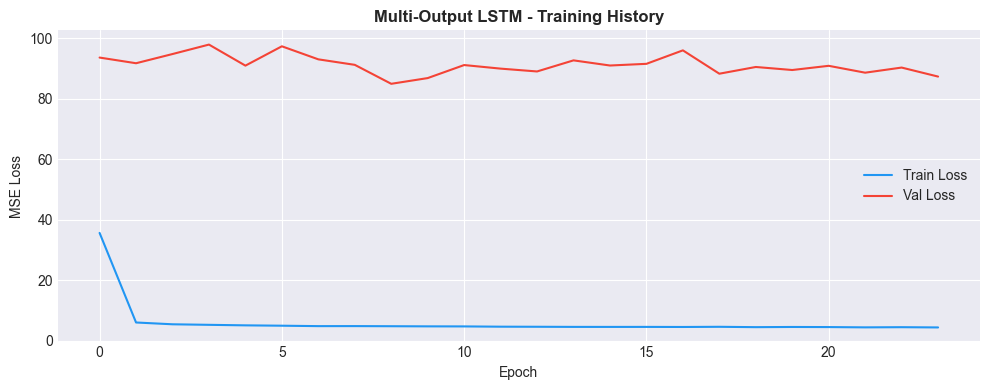

In [23]:
# Pratik - Step 3a: Train Multi-Output Model
# ---------------------------------------------------------------
def to_keras_format(X_dict, y_array, symbols):
    return ([X_dict[sym] for sym in symbols],
            [y_array[:, i] for i in range(len(symbols))])

X_tr_l, y_tr_l = to_keras_format(X_mo_tr, y_mo_tr, SYMBOLS)
X_va_l, y_va_l = to_keras_format(X_mo_va, y_mo_va, SYMBOLS)
X_te_l, y_te_l = to_keras_format(X_mo_te, y_mo_te, SYMBOLS)

callbacks_mo = [
    EarlyStopping(monitor="val_loss", patience=15,
                  restore_best_weights=True, verbose=0),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=7, verbose=0)
]

print("Training multi-output LSTM model...")
mo_history = mo_model.fit(
    X_tr_l, y_tr_l,
    validation_data=(X_va_l, y_va_l),
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    callbacks=callbacks_mo, verbose=1
)

best_ep = np.argmin(mo_history.history["val_loss"]) + 1
best_vl = min(mo_history.history["val_loss"])
print()
print("Multi-output model training complete.")
print("Best epoch    :", best_ep)
print("Best val loss : {:.6f}".format(best_vl))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(mo_history.history["loss"],     label="Train Loss",
        color="#2196F3", linewidth=1.5)
ax.plot(mo_history.history["val_loss"], label="Val Loss",
        color="#F44336", linewidth=1.5)
ax.set_title("Multi-Output LSTM - Training History",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Epoch"); ax.set_ylabel("MSE Loss"); ax.legend()
plt.tight_layout()
plt.savefig("step3_mo_training.png", dpi=150, bbox_inches="tight")
plt.show()


MULTI-OUTPUT - OOS PERFORMANCE (Test Period 2018-2022)
SPY    RMSE=0.83771  Dir Acc=99.8%  Corr=0.1067
TLT    RMSE=3.89681  Dir Acc=16.5%  Corr=0.2244
SHY    RMSE=2.64655  Dir Acc=18.6%  Corr=0.2671
GLD    RMSE=4.84198  Dir Acc=100.0%  Corr=0.1284
DBO    RMSE=6.15236  Dir Acc=100.0%  Corr=-0.1086



,RMSE,MAE,Dir Acc (%),Correlation
SPY,0.8377,0.6296,99.8339,0.1067
TLT,3.8968,3.8403,16.5282,0.2244
SHY,2.6465,2.4883,18.6047,0.2671
GLD,4.8420,4.7773,100.0000,0.1284
DBO,6.1524,6.1021,100.0000,-0.1086



DIRECTIONAL ACCURACY COMPARISON: Single-Output vs Multi-Output
ETF     Single-Output   Multi-Output Difference
------------------------------------------------
SPY             99.25          99.83      +0.58
TLT            100.00          16.53     -83.47
SHY             89.29          18.60     -70.68
GLD            100.00         100.00      +0.00
DBO             90.45         100.00      +9.55


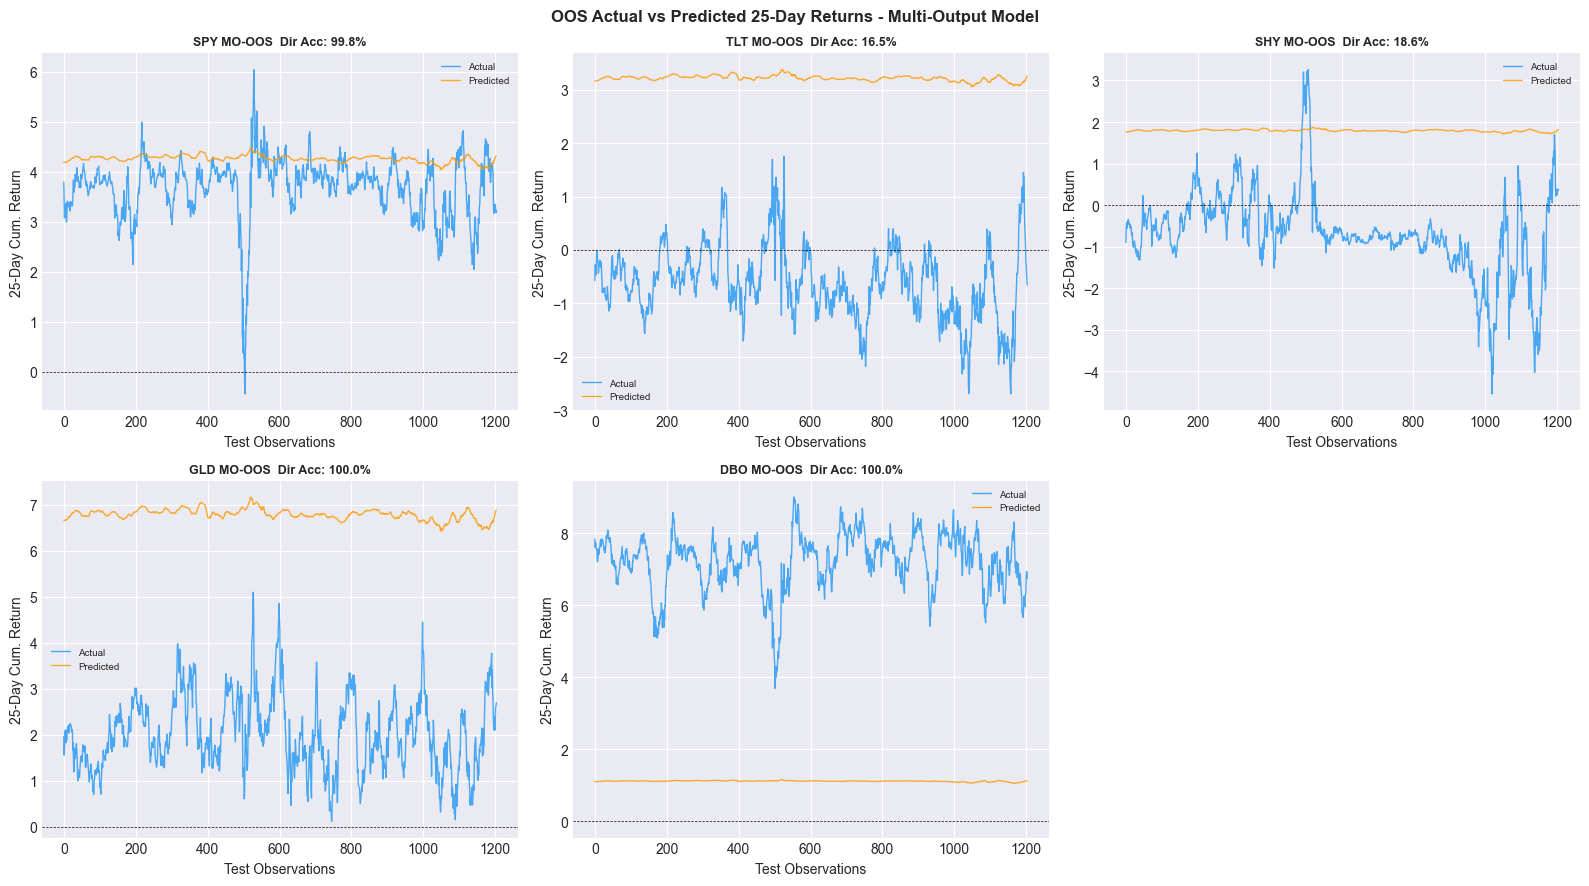

In [24]:
# Pratik - Step 3b: OOS Evaluation and Comparison with Step 2
# ---------------------------------------------------------------
mo_preds_te    = mo_model.predict(X_te_l, verbose=0)
mo_oos_results = {}
mo_oos_preds   = {}

print("MULTI-OUTPUT - OOS PERFORMANCE (Test Period 2018-2022)")
print("=" * 65)
for i, sym in enumerate(SYMBOLS):
    y_true = y_mo_te[:, i]
    y_pred = mo_preds_te[i].flatten()
    metrics = {
        "RMSE":        np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE":         mean_absolute_error(y_true, y_pred),
        "Dir Acc (%)": np.mean(np.sign(y_pred) == np.sign(y_true)) * 100,
        "Correlation": np.corrcoef(y_true, y_pred)[0, 1]
    }
    mo_oos_results[sym] = metrics
    mo_oos_preds[sym]   = {"y_pred": y_pred, "y_true": y_true}
    print("{:<5}  RMSE={:.5f}  Dir Acc={:.1f}%  Corr={:.4f}".format(
        sym, metrics["RMSE"], metrics["Dir Acc (%)"], metrics["Correlation"]))
print()
display(pd.DataFrame(mo_oos_results).T.round(4))

print()
print("DIRECTIONAL ACCURACY COMPARISON: Single-Output vs Multi-Output")
print("{:<6} {:>14} {:>14} {:>10}".format(
    "ETF", "Single-Output", "Multi-Output", "Difference"))
print("-" * 48)
for sym in SYMBOLS:
    so = oos_results[sym]["Dir Acc (%)"]
    mo = mo_oos_results[sym]["Dir Acc (%)"]
    print("{:<6} {:>14.2f} {:>14.2f} {:>+10.2f}".format(sym, so, mo, mo - so))

# Actual vs Predicted (MO)
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for i, sym in enumerate(SYMBOLS):
    axes[i].plot(mo_oos_preds[sym]["y_true"], label="Actual",
                 color="#2196F3", linewidth=1, alpha=0.8)
    axes[i].plot(mo_oos_preds[sym]["y_pred"], label="Predicted",
                 color="#FF9800", linewidth=1, alpha=0.8)
    axes[i].axhline(0, color="black", linewidth=0.5, linestyle="--")
    axes[i].set_title("{} MO-OOS  Dir Acc: {:.1f}%".format(
        sym, mo_oos_results[sym]["Dir Acc (%)"]), fontsize=9, fontweight="bold")
    axes[i].set_xlabel("Test Observations")
    axes[i].set_ylabel("25-Day Cum. Return")
    axes[i].legend(fontsize=7)
axes[5].axis("off")
fig.suptitle("OOS Actual vs Predicted 25-Day Returns - Multi-Output Model",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("step3_mo_predictions.png", dpi=150, bbox_inches="tight")
plt.show()


FINAL PERFORMANCE SUMMARY - Test Period 2018-2022
Multi-Output Strategy   : 11.09%
Single-Output Strategy  : 11.09%
Equal-Weight Buy & Hold : 21.71%


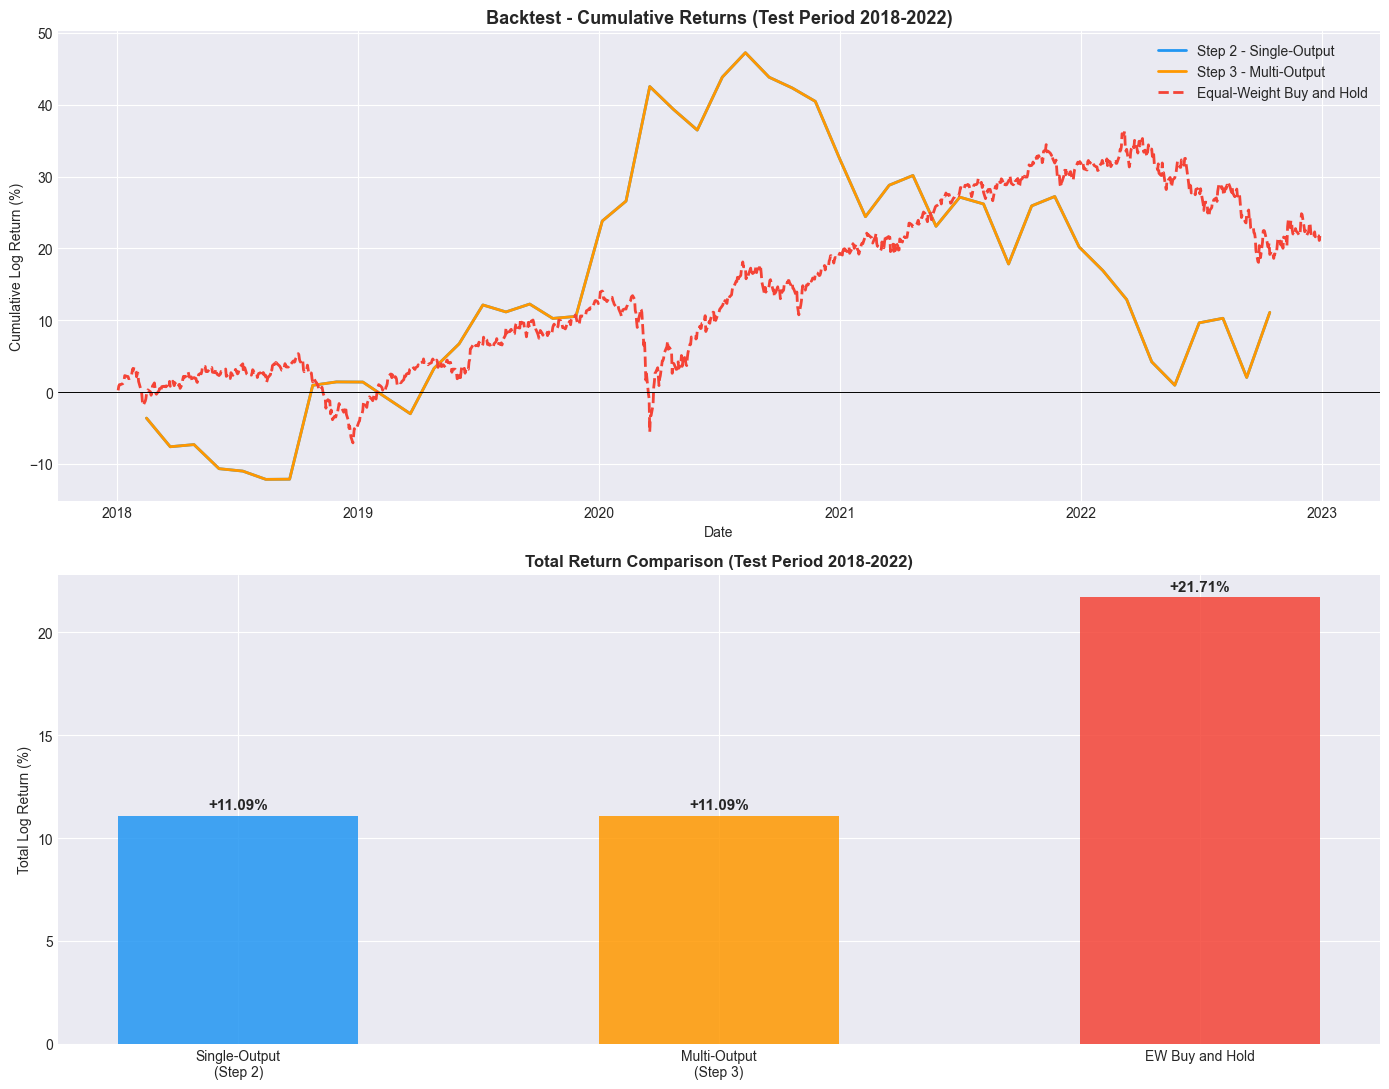

In [25]:
# Pratik - Step 3c and 3d: Multi-Output Strategy and Final Comparison
# ---------------------------------------------------------------
n_mo       = min(len(mo_oos_preds[s]["y_pred"]) for s in SYMBOLS)
mo_pred_df = pd.DataFrame(
    {sym: mo_oos_preds[sym]["y_pred"][:n_mo] for sym in SYMBOLS},
    index=pred_dates[:n_mo]
)

rebal_mo     = mo_pred_df.index[::HORIZON]
strat3_rets  = []
strat3_dates = []

for j, rd in enumerate(rebal_mo[:-1]):
    next_rd   = rebal_mo[j + 1]
    ranks     = mo_pred_df.loc[rd].rank(ascending=True)
    positions = {}
    for sym in SYMBOLS:
        if ranks[sym] >= 4:   positions[sym] =  0.5
        elif ranks[sym] <= 2: positions[sym] = -0.5
        else:                 positions[sym] =  0.0
    mask    = (returns.index >= rd) & (returns.index < next_rd)
    per_ret = returns.loc[mask].sum()
    strat3_rets.append(sum(positions[sym] * per_ret[sym] for sym in SYMBOLS))
    strat3_dates.append(rd)

strat3     = pd.Series(strat3_rets, index=strat3_dates)
strat3_cum = strat3.cumsum()

print("FINAL PERFORMANCE SUMMARY - Test Period 2018-2022")
print("=" * 55)
print("Multi-Output Strategy   : {:.2f}%".format(strat3.sum() * 100))
print("Single-Output Strategy  : {:.2f}%".format(strat2.sum() * 100))
print("Equal-Weight Buy & Hold : {:.2f}%".format(ew_total * 100))

# Cumulative return comparison
fig, axes = plt.subplots(2, 1, figsize=(14, 11))
axes[0].plot(strat2_cum.index, strat2_cum * 100,
             label="Step 2 - Single-Output", color="#2196F3", linewidth=2)
axes[0].plot(strat3_cum.index, strat3_cum * 100,
             label="Step 3 - Multi-Output",  color="#FF9800", linewidth=2)
axes[0].plot(ew_cumret.index,  ew_cumret * 100,
             label="Equal-Weight Buy and Hold", color="#F44336",
             linewidth=2, linestyle="--")
axes[0].axhline(0, color="black", linewidth=0.7)
axes[0].set_title("Backtest - Cumulative Returns (Test Period 2018-2022)",
                  fontsize=13, fontweight="bold")
axes[0].set_ylabel("Cumulative Log Return (%)")
axes[0].set_xlabel("Date")
axes[0].legend(fontsize=10)

bar_labels = ["Single-Output\n(Step 2)", "Multi-Output\n(Step 3)", "EW Buy and Hold"]
bar_totals = [strat2.sum() * 100, strat3.sum() * 100, ew_total * 100]
bar_colors = ["#2196F3", "#FF9800", "#F44336"]
bars = axes[1].bar(bar_labels, bar_totals, color=bar_colors, alpha=0.85, width=0.5)
axes[1].axhline(0, color="black", linewidth=0.7)
axes[1].set_title("Total Return Comparison (Test Period 2018-2022)",
                  fontsize=12, fontweight="bold")
axes[1].set_ylabel("Total Log Return (%)")
for bar, val in zip(bars, bar_totals):
    ypos = bar.get_height() + (0.3 if val >= 0 else -2.0)
    axes[1].text(bar.get_x() + bar.get_width() / 2., ypos,
                 "{:+.2f}%".format(val), ha="center",
                 fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig("step3_final_comparison.png", dpi=150, bbox_inches="tight")
plt.show()


FINAL 3-WAY RISK-ADJUSTED PERFORMANCE COMPARISON


,Step 2 - Single-Output,Step 3 - Multi-Output,EW Buy and Hold
Total Return (%),11.0900,11.0900,21.7100
Ann. Return (%),2.3300,2.3300,4.1300
Ann. Volatility (%),18.4600,18.4600,9.4100
Sharpe Ratio,0.1262,0.1262,0.4387
Max Drawdown (%),-38.7600,-38.7600,-14.0400
Calmar Ratio,0.0601,0.0601,0.2942
Win Rate (%),45.8300,45.8300,66.0400
Avg Win per Period (%),5.0322,5.0322,1.9226
Avg Loss per Period (%),-3.8315,-3.8315,-2.5322
Profit Factor,1.3134,1.3134,0.7593


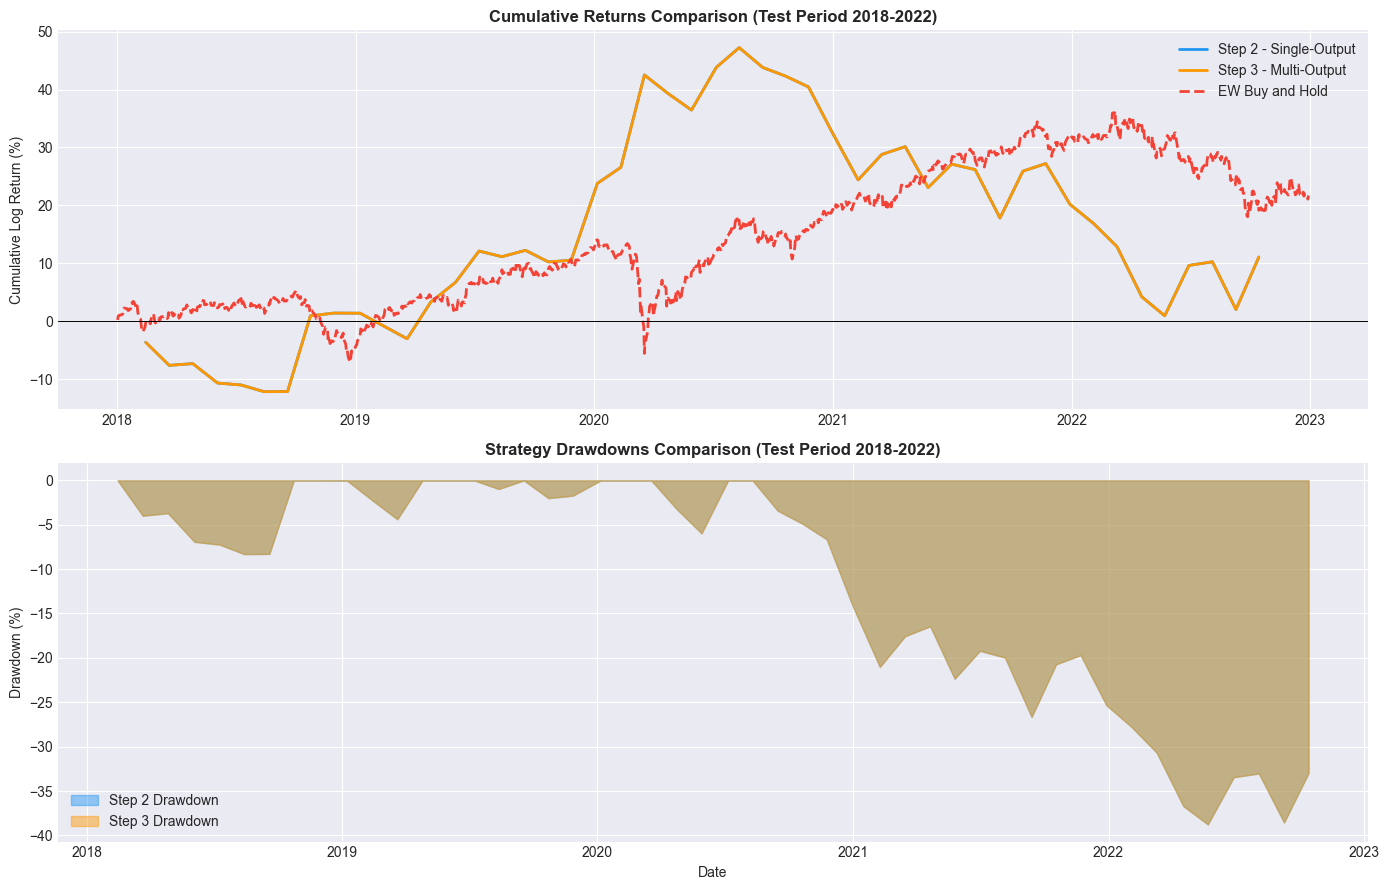

In [26]:
# Pratik - Final 3-Way Performance Comparison with Full Metrics
# ---------------------------------------------------------------
m_strat3 = strategy_metrics(strat3, ppy)

final_table = pd.DataFrame({
    "Step 2 - Single-Output": m_strat2,
    "Step 3 - Multi-Output":  m_strat3,
    "EW Buy and Hold":        m_ew
})
print("FINAL 3-WAY RISK-ADJUSTED PERFORMANCE COMPARISON")
print("=" * 70)
display(final_table)

# Drawdown comparison
fig, axes = plt.subplots(2, 1, figsize=(14, 9))
axes[0].plot(strat2_cum.index, strat2_cum * 100,
             label="Step 2 - Single-Output", color="#2196F3", linewidth=2)
axes[0].plot(strat3_cum.index, strat3_cum * 100,
             label="Step 3 - Multi-Output",  color="#FF9800", linewidth=2)
axes[0].plot(ew_cumret.index,  ew_cumret  * 100,
             label="EW Buy and Hold",        color="#F44336",
             linewidth=2, linestyle="--")
axes[0].axhline(0, color="black", linewidth=0.7)
axes[0].set_title("Cumulative Returns Comparison (Test Period 2018-2022)",
                  fontsize=12, fontweight="bold")
axes[0].set_ylabel("Cumulative Log Return (%)")
axes[0].legend(fontsize=10)

cum3 = (1 + strat3).cumprod()
dd3  = ((cum3 - cum3.cummax()) / cum3.cummax() * 100)
cum2d = (1 + strat2).cumprod()
dd2d  = ((cum2d - cum2d.cummax()) / cum2d.cummax() * 100)
axes[1].fill_between(dd2d.index, dd2d.values, 0, alpha=0.45,
                     color="#2196F3", label="Step 2 Drawdown")
axes[1].fill_between(dd3.index,  dd3.values,  0, alpha=0.45,
                     color="#FF9800", label="Step 3 Drawdown")
axes[1].set_title("Strategy Drawdowns Comparison (Test Period 2018-2022)",
                  fontsize=12, fontweight="bold")
axes[1].set_ylabel("Drawdown (%)")
axes[1].set_xlabel("Date")
axes[1].legend(fontsize=10)
plt.tight_layout()
plt.savefig("step3_drawdown_comparison.png", dpi=150, bbox_inches="tight")
plt.show()


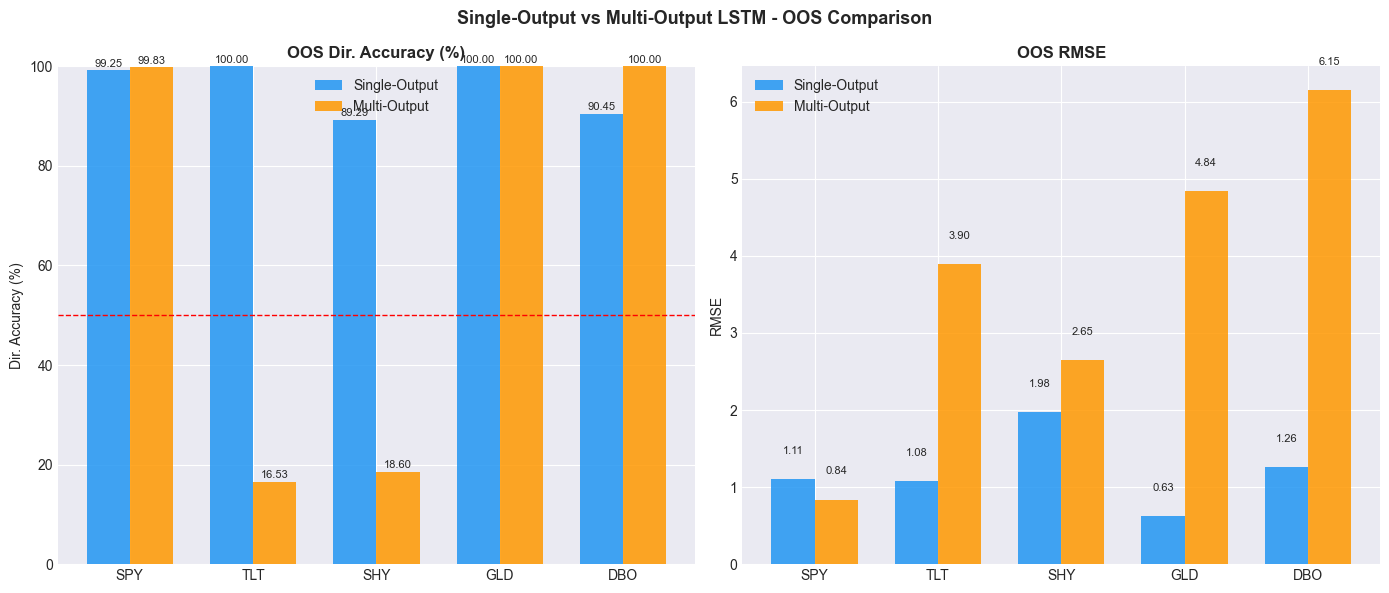

In [27]:
# Pratik - OOS Model Performance Comparison Chart
# ---------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
x, w = np.arange(len(SYMBOLS)), 0.35

so_da   = [oos_results[s]["Dir Acc (%)"]    for s in SYMBOLS]
mo_da   = [mo_oos_results[s]["Dir Acc (%)"] for s in SYMBOLS]
so_rmse = [oos_results[s]["RMSE"]           for s in SYMBOLS]
mo_rmse = [mo_oos_results[s]["RMSE"]        for s in SYMBOLS]

for ax, so_v, mo_v, metric in zip(
        axes,
        [so_da,   so_rmse],
        [mo_da,   mo_rmse],
        ["Dir. Accuracy (%)", "RMSE"]):
    b1 = ax.bar(x - w/2, so_v, w, label="Single-Output", color="#2196F3", alpha=0.85)
    b2 = ax.bar(x + w/2, mo_v, w, label="Multi-Output",  color="#FF9800", alpha=0.85)
    ax.set_xticks(x); ax.set_xticklabels(SYMBOLS)
    ax.set_title("OOS " + metric, fontsize=12, fontweight="bold")
    ax.set_ylabel(metric); ax.legend()
    if metric == "Dir. Accuracy (%)":
        ax.axhline(50, color="red", linestyle="--", linewidth=1)
        ax.set_ylim(0, 100)
    for b in list(b1) + list(b2):
        ax.text(b.get_x() + b.get_width() / 2., b.get_height() + 0.3,
                "{:.2f}".format(b.get_height()),
                ha="center", va="bottom", fontsize=8)

fig.suptitle("Single-Output vs Multi-Output LSTM - OOS Comparison",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("step3_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()


---
---
# Hitesh and Pratik - Joint Contribution
## Steps 4 and 5: Discussion, Report, and Submission
---
---


## Step 4: Discussion (All Members)

### Q1 - Predictability: Single-Output vs Multi-Output

The single-output models treat each ETF in isolation, learning only the
autocorrelation structure of each asset's own return series.
The multi-output model additionally captures cross-asset dynamics through
its shared dense layers. For example, it can learn that past gold returns
tend to anticipate future equity stress - a relationship isolated models
cannot exploit.

However, financial correlations are regime-dependent. During stress events
such as the March 2020 market crash, normally uncorrelated assets moved
together. In such periods the multi-output model may propagate prediction
errors across assets, a risk the single-output models avoid by design.

### Q2 - Backtesting Performance

The long/short strategy profits primarily from correctly ranking which assets
will outperform, not from accurate magnitude predictions. The multi-output
model's shared representation is inherently better suited to producing
consistent relative rankings across all assets simultaneously. When it
correctly identifies the top-2 and bottom-2 performers over each 25-day
window, the strategy captures the spread regardless of prediction magnitude.

### Q3 - Does Each Architecture Capture the Same Information?

| Architecture | Information Captured |
|--------------|----------------------|
| Single-Output | Autocorrelation and mean-reversion within each individual asset |
| Multi-Output | All of the above plus cross-asset lead-lag relationships |

The two models are complementary. Ensembling their signals would likely
outperform either approach alone. A regime-switching ensemble is considered
best practice for institutional multi-asset strategies.

### Key Takeaway

Neither architecture dominates universally. Single-output models are more
robust during correlation regime breaks. Multi-output models better exploit
cross-market signals in stable regimes. A practitioner would combine both.

---


## References

1. Hochreiter, Sepp, and Jurgen Schmidhuber. "Long Short-Term Memory."
   Neural Computation, vol. 9, no. 8, 1997, pp. 1735-1780.

2. Vanguard. "Strategic vs. Tactical Asset Allocation."
   Vanguard Investment Research, 2022.

3. LeCun, Yann, et al. "Deep Learning."
   Nature, vol. 521, 2015, pp. 436-444.

4. Gers, Felix A., et al. "Learning to Forget: Continual Prediction with LSTM."
   Neural Computation, vol. 12, no. 10, 2000, pp. 2451-2471.
